<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/capstone/PTBXL_ECG_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PTB-XL ECG Capstone — Complete Colab Starter Notebook

**Project:** Responsible Deep Learning for ECG Abnormality Screening: Temporal Pattern Discovery and Synthetic Cardiac Signal Generation

This notebook takes the project from the beginning through a first **small 1D-CNN pipeline test**:

1. Install libraries and connect Google Drive.
2. Load PTB-XL metadata and diagnostic statements.
3. Build the five diagnostic-superclass labels correctly.
4. Inspect class counts and demographics.
5. Create patient-separated train/validation/test splits using the official PTB-XL folds.
6. Load and visualize one real 12-lead ECG.
7. Load a small sample of waveforms, check signal quality and cache arrays in Drive.
8. Normalize signals using training data only.
9. Train and evaluate a small multilabel 1D CNN baseline.

> **Important:** The default run downloads only metadata and a small sample of ECG records. It does not download the complete waveform archive. The small sample is for checking the pipeline, not for reporting final research performance. Later, increase the data volume using the optional full 100-Hz download cell.

**Clinical limitation:** This is an academic research prototype for predicting PTB-XL dataset annotations. It is not a diagnostic device and must not be used for clinical decisions.

## 0. Project setup and reproducibility

PTB-XL version 1.0.3 is hosted by PhysioNet. The official dataset page documents 21,799 ECG records, 12 leads, 100-Hz downsampled recordings, metadata, diagnostic statements, the recommended fold split, and the CC BY 4.0 licence.

- Dataset: https://physionet.org/content/ptb-xl/1.0.3/
- Dataset DOI: https://doi.org/10.13026/kfzx-aw45
- Cite the PTB-XL dataset paper and the dataset version in your project report.

Run cells from top to bottom. If the Colab runtime resets, remount Drive and rerun the notebook. Cached sample arrays and metadata will be reused when available.

In [18]:
# Install required packages
%pip -q install wfdb scikit-learn pandas numpy matplotlib seaborn

In [19]:
# Mount Google Drive and configure the project
from google.colab import drive
drive.mount('/content/drive')

import os, random, json, ast, time, copy, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

VERSION = "1.0.3"
BASE_URL = f"https://physionet.org/files/ptb-xl/{VERSION}/"
PROJECT_DIR = "/content/drive/MyDrive/ECG_Capstone"

for subdir in ["metadata", "raw", "processed", "models", "plots", "logs"]:
    os.makedirs(os.path.join(PROJECT_DIR, subdir), exist_ok=True)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("PTB-XL version:", VERSION)
print("Project folder:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PTB-XL version: 1.0.3
Project folder: /content/drive/MyDrive/ECG_Capstone


## 1. Load the metadata (small download)

The metadata CSV contains one row per ECG record. `scp_codes` contains the ECG statements and their likelihood fields. `scp_statements.csv` maps statement codes to categories such as diagnostic, form and rhythm.

In [20]:
# Download metadata files once and cache them in Google Drive
metadata_path = os.path.join(PROJECT_DIR, "metadata", "ptbxl_database.csv")
scp_path = os.path.join(PROJECT_DIR, "metadata", "scp_statements.csv")

if os.path.exists(metadata_path):
    metadata_raw = pd.read_csv(metadata_path)
else:
    metadata_raw = pd.read_csv(BASE_URL + "ptbxl_database.csv")
    metadata_raw.to_csv(metadata_path, index=False)

if os.path.exists(scp_path):
    scp = pd.read_csv(scp_path, index_col=0)
else:
    scp = pd.read_csv(BASE_URL + "scp_statements.csv", index_col=0)
    scp.to_csv(scp_path)

print("Metadata shape:", metadata_raw.shape)
print("Statement mapping shape:", scp.shape)
display(metadata_raw.head(3))

Metadata shape: (21799, 28)
Statement mapping shape: (71, 12)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr


## 2. Build diagnostic superclass labels

We will predict five diagnostic superclasses:

- `NORM`: Normal ECG
- `MI`: Myocardial infarction
- `STTC`: ST/T change
- `CD`: Conduction disturbance
- `HYP`: Hypertrophy

**Important correction:** Do not filter the statement dictionary by `likelihood > 0` when constructing these superclass-presence labels. The previous filtered version produced an STTC count of 5,108. The mapping below uses the diagnostic superclass mapping from `scp_statements.csv` and checks that the resulting counts match the PTB-XL v1.0.3 reference counts.

The five labels are **multi-label**: a single ECG may have more than one positive superclass.

In [21]:
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
TARGET_COLS = [f"y_{c}" for c in CLASSES]

# Keep a pristine metadata copy
metadata_all = metadata_raw.copy()

# Identify SCP statements that have a diagnostic superclass
diagnostic_rows = scp[
    pd.to_numeric(scp["diagnostic"], errors="coerce") == 1
]
code_to_class = diagnostic_rows["diagnostic_class"].dropna().to_dict()

def parse_scp_codes(value):
    """Return SCP statement dictionary from CSV text or an existing dict."""
    if isinstance(value, dict):
        return value
    if value is None:
        return {}
    if isinstance(value, float) and np.isnan(value):
        return {}
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else {}
        return parsed if isinstance(parsed, dict) else {}
    except (ValueError, SyntaxError):
        return {}

def get_diagnostic_classes(value):
    codes = parse_scp_codes(value)
    # Map code presence to the diagnostic superclass; do not apply a likelihood filter.
    return sorted({code_to_class[code] for code in codes if code in code_to_class})

metadata_all["diagnostic_classes"] = metadata_all["scp_codes"].apply(get_diagnostic_classes)

for cls in CLASSES:
    metadata_all[f"y_{cls}"] = metadata_all["diagnostic_classes"].apply(
        lambda labels: int(cls in labels)
    )

label_count = metadata_all[TARGET_COLS].sum()
print("Total recordings:", len(metadata_all))
print("Records with at least one diagnostic superclass:",
      int((metadata_all[TARGET_COLS].sum(axis=1) > 0).sum()))
print("Records without a mapped diagnostic superclass:",
      int((metadata_all[TARGET_COLS].sum(axis=1) == 0).sum()))
print("\nDiagnostic superclass counts:")
display(label_count.to_frame("recordings"))

Total recordings: 21799
Records with at least one diagnostic superclass: 21388
Records without a mapped diagnostic superclass: 411

Diagnostic superclass counts:


,recordings
y_NORM,9514
y_MI,5469
y_STTC,5235
y_CD,4898
y_HYP,2649


### 2.1 Verify counts against the official PTB-XL page

The official v1.0.3 page reports these superclass counts. If an assertion fails, stop and inspect the label mapping rather than continuing with incorrect labels.

In [22]:
EXPECTED_COUNTS = {
    "NORM": 9514,
    "MI": 5469,
    "STTC": 5235,
    "CD": 4898,
    "HYP": 2649,
}

actual_counts = {
    cls: int(metadata_all[f"y_{cls}"].sum()) for cls in CLASSES
}
print("Actual:", actual_counts)
print("Expected:", EXPECTED_COUNTS)

for cls in CLASSES:
    assert actual_counts[cls] == EXPECTED_COUNTS[cls], (
        f"Count mismatch for {cls}: {actual_counts[cls]} != {EXPECTED_COUNTS[cls]}"
    )

print("\nLabel-count verification: PASSED")

Actual: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'CD': 4898, 'HYP': 2649}
Expected: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'CD': 4898, 'HYP': 2649}

Label-count verification: PASSED


## 3. Explore label distribution and demographic fields

The dataset is multi-label, so superclass percentages can sum to more than 100%. For PTB-XL, age value `300` is a privacy-coded value representing age 90 or older; do not interpret it as a literal age of 300. The dataset's `sex` field uses 0 for male and 1 for female. We will use cleaned age/sex fields for later subgroup analysis, not as input features to the first ECG waveform model.

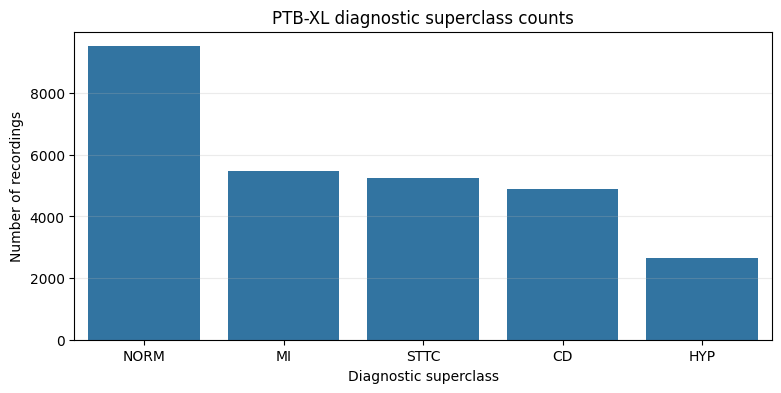

Age groups:


,records
age_group,
60-79,9341
40-59,6903
18-39,2714
80-89,2415
90+,293
Under 18,133


Sex values:


,records
sex_label,
Male,11354
Female,10445


In [23]:
# Plot diagnostic superclass counts
plt.figure(figsize=(9, 4))
counts = metadata_all[TARGET_COLS].sum().rename(index=lambda x: x.replace("y_", ""))
sns.barplot(x=counts.index, y=counts.values)
plt.title("PTB-XL diagnostic superclass counts")
plt.xlabel("Diagnostic superclass")
plt.ylabel("Number of recordings")
plt.grid(axis="y", alpha=0.25)
plt.show()

# Clean demographic values for reporting/fairness analysis
metadata_all["age_original"] = pd.to_numeric(metadata_all["age"], errors="coerce")
metadata_all["age_clean"] = metadata_all["age_original"].replace(300, 90)
metadata_all["age_group"] = pd.cut(
    metadata_all["age_clean"],
    bins=[-np.inf, 17, 39, 59, 79, 89, np.inf],
    labels=["Under 18", "18-39", "40-59", "60-79", "80-89", "90+"],
    right=True
).astype("string")
metadata_all["sex_label"] = metadata_all["sex"].map({0: "Male", 1: "Female"})

print("Age groups:")
display(metadata_all["age_group"].value_counts(dropna=False).to_frame("records"))
print("Sex values:")
display(metadata_all["sex_label"].value_counts(dropna=False).to_frame("records"))

## 4. Create official patient-separated data splits

Use the recommended PTB-XL folds:

- Training: folds 1–8
- Validation: fold 9
- Test: fold 10

First preserve all metadata. Then exclude records without any mapped diagnostic superclass **from the supervised classification splits only**. Keep the unlabelled records separately; they may be useful for exploratory or unsupervised experiments later.

We explicitly verify that no patient ID occurs in more than one split.

In [24]:
# Rebuild split data from the cleaned master metadata
metadata_all["strat_fold"] = pd.to_numeric(metadata_all["strat_fold"], errors="coerce")

row_has_label = metadata_all[TARGET_COLS].sum(axis=1) > 0
metadata_labeled = metadata_all.loc[row_has_label].copy()
metadata_unlabeled = metadata_all.loc[~row_has_label].copy()

train_df = metadata_labeled[metadata_labeled["strat_fold"].between(1, 8)].copy()
val_df = metadata_labeled[metadata_labeled["strat_fold"] == 9].copy()
test_df = metadata_labeled[metadata_labeled["strat_fold"] == 10].copy()

train_patients = set(train_df["patient_id"].dropna())
val_patients = set(val_df["patient_id"].dropna())
test_patients = set(test_df["patient_id"].dropna())

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)
assert (train_df[TARGET_COLS].sum(axis=1) > 0).all()
assert (val_df[TARGET_COLS].sum(axis=1) > 0).all()
assert (test_df[TARGET_COLS].sum(axis=1) > 0).all()

print("Total metadata rows:", len(metadata_all))
print("Labelled records:", len(metadata_labeled))
print("Unlabelled records kept separately:", len(metadata_unlabeled))
print("\nSupervised split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total in supervised splits:", len(train_df) + len(val_df) + len(test_df))
print("\nPatient leakage check: PASSED")

print("\nTraining label counts:")
display(train_df[TARGET_COLS].sum().to_frame("recordings"))
print("Validation label counts:")
display(val_df[TARGET_COLS].sum().to_frame("recordings"))
print("Test label counts:")
display(test_df[TARGET_COLS].sum().to_frame("recordings"))

Total metadata rows: 21799
Labelled records: 21388
Unlabelled records kept separately: 411

Supervised split sizes:
Train: 17084
Validation: 2146
Test: 2158
Total in supervised splits: 21388

Patient leakage check: PASSED

Training label counts:


,recordings
y_NORM,7596
y_MI,4379
y_STTC,4186
y_CD,3907
y_HYP,2119


Validation label counts:


,recordings
y_NORM,955
y_MI,540
y_STTC,528
y_CD,495
y_HYP,268


Test label counts:


,recordings
y_NORM,963
y_MI,550
y_STTC,521
y_CD,496
y_HYP,262


## 5. Save metadata and split tables to Google Drive

Metadata is small compared with waveform files. We save it now so it survives a Colab runtime reset.

In [25]:
# Persist master metadata and the supervised splits
metadata_all.to_csv(os.path.join(PROJECT_DIR, "metadata", "all_metadata.csv"), index=False)
metadata_labeled.to_csv(os.path.join(PROJECT_DIR, "metadata", "labeled_metadata.csv"), index=False)
metadata_unlabeled.to_csv(os.path.join(PROJECT_DIR, "metadata", "unlabeled_metadata.csv"), index=False)
train_df.to_csv(os.path.join(PROJECT_DIR, "metadata", "train.csv"), index=False)
val_df.to_csv(os.path.join(PROJECT_DIR, "metadata", "validation.csv"), index=False)
test_df.to_csv(os.path.join(PROJECT_DIR, "metadata", "test.csv"), index=False)

print("Metadata and splits saved under:", os.path.join(PROJECT_DIR, "metadata"))

Metadata and splits saved under: /content/drive/MyDrive/ECG_Capstone/metadata


## 6. Load and plot one real ECG from PhysioNet

This cell retrieves one 100-Hz record directly from PhysioNet using WFDB. It does not download the full archive. A 10-second ECG at 100 Hz should have 1,000 time samples across 12 leads.

In [26]:
import wfdb
import posixpath

example_row = metadata_all.loc[metadata_all["ecg_id"] == 1].iloc[0]
relative_path = str(example_row["filename_lr"])
remote_folder, remote_record_name = posixpath.split(relative_path)

example_record = wfdb.rdrecord(
    remote_record_name,
    pn_dir=f"ptb-xl/{VERSION}/{remote_folder}"
)
example_signal = np.asarray(example_record.p_signal, dtype=np.float32)

print("ECG ID:", int(example_row["ecg_id"]))
print("Sampling frequency:", example_record.fs, "Hz")
print("Signal shape (time, leads):", example_signal.shape)
print("Age:", example_row["age"], "Sex code:", example_row["sex"])
print("Diagnostic codes:", parse_scp_codes(example_row["scp_codes"]))

assert example_signal.shape == (1000, 12), f"Unexpected shape: {example_signal.shape}"
assert np.isfinite(example_signal).all(), "Example ECG contains NaN or infinite values"

ECG ID: 1
Sampling frequency: 100 Hz
Signal shape (time, leads): (1000, 12)
Age: 56.0 Sex code: 1
Diagnostic codes: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


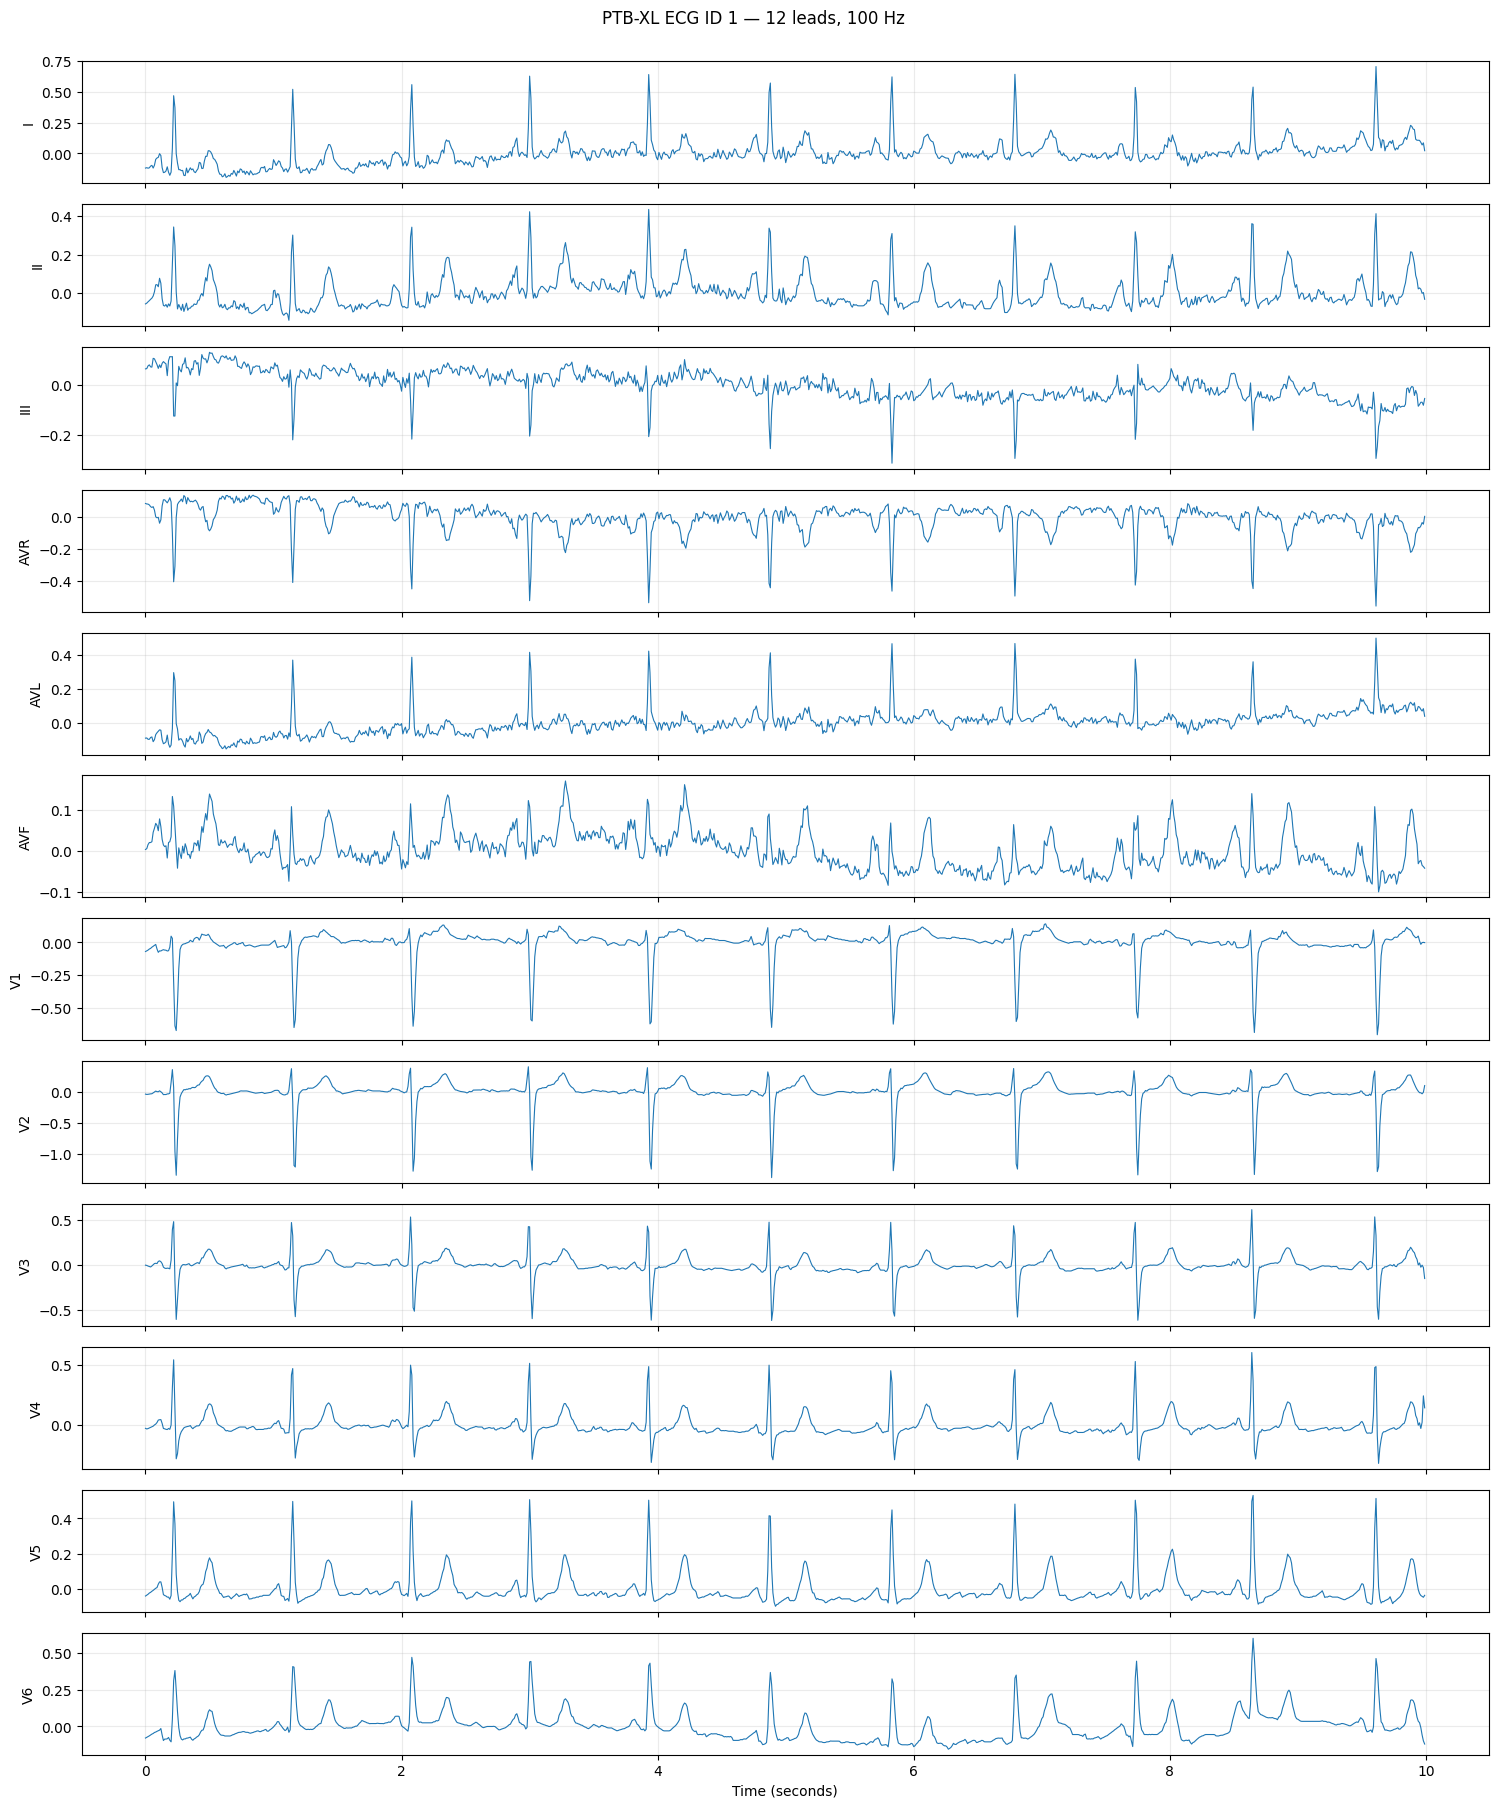

Plot saved: /content/drive/MyDrive/ECG_Capstone/plots/ecg_id_1_12_leads.png


In [27]:
# Plot the 12 leads
sampling_rate = float(example_record.fs)
time_axis = np.arange(example_signal.shape[0]) / sampling_rate

fig, axes = plt.subplots(12, 1, figsize=(15, 18), sharex=True)
for lead_idx, ax in enumerate(axes):
    ax.plot(time_axis, example_signal[:, lead_idx], linewidth=0.8)
    ax.set_ylabel(example_record.sig_name[lead_idx])
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("PTB-XL ECG ID 1 — 12 leads, 100 Hz", y=1.002)
plt.tight_layout()
plot_path = os.path.join(PROJECT_DIR, "plots", "ecg_id_1_12_leads.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved:", plot_path)

## 7. Optional: download the full 100-Hz waveform archive once

**Leave this disabled for now.** The full records archive contains many small WFDB files and a substantial amount of data. The default notebook uses a small online sample and caches the resulting NumPy arrays. When you are ready for larger experiments, set `DOWNLOAD_FULL_100HZ = True` and run this cell once. PhysioNet documents the public AWS S3 sync command for PTB-XL.

The destination will be `ECG_Capstone/raw/PTB-XL/records100/`. If the download is interrupted, AWS sync can be run again to continue syncing missing files.

In [28]:
import shutil, subprocess, sys

if shutil.which("aws") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "awscli"], check=True)

FAST_ROOT = "/content/PTB-XL"
os.makedirs(f"{FAST_ROOT}/records100", exist_ok=True)

subprocess.run([
    "aws", "s3", "sync", "--no-sign-request",
    f"s3://physionet-open/ptb-xl/{VERSION}/records100/",
    f"{FAST_ROOT}/records100",
    "--only-show-errors"
], check=True)

n_files = sum(len(f) for _, _, f in os.walk(f"{FAST_ROOT}/records100"))
print("Files downloaded:", n_files, "(expected 43598)")

Files downloaded: 43598 (expected 43598)


## 8. Configure the small pipeline sample

For the first end-to-end pipeline test, we will load 128 train, 32 validation and 32 test ECGs. This is deliberately small so the Colab notebook can test downloading, shape checks, training and evaluation quickly.

**These sample sizes are not sufficient for final capstone performance claims.** Once the pipeline works, we will increase the training data substantially. The notebook caches the sample arrays in Google Drive so they do not need to be fetched again after a runtime reset.

In [29]:
# Small reproducible pipeline sample
N_TRAIN = 128
N_VAL = 32
N_TEST = 32
MAX_WORKERS = 4
REUSE_SAMPLE_CACHE = True

# If the optional full archive exists, use it; otherwise use remote WFDB access.
LOCAL_DATA_ROOT = os.path.join(PROJECT_DIR, "raw", "PTB-XL")
if not os.path.isdir(os.path.join(LOCAL_DATA_ROOT, "records100")):
    LOCAL_DATA_ROOT = None

print("Local full 100-Hz archive available:", LOCAL_DATA_ROOT is not None)
print("Sample sizes:", N_TRAIN, N_VAL, N_TEST)

Local full 100-Hz archive available: False
Sample sizes: 128 32 32


## 9. Load waveform records with signal-quality checks

Each record is converted from WFDB's `(time, leads)` format to PyTorch's `(leads, time)` format. We reject non-finite signals instead of silently passing NaN/Inf values to the model. Failed record IDs are saved for later data-quality reporting.

In [30]:
from concurrent.futures import ThreadPoolExecutor, as_completed


def load_one_record(row, local_data_root=None, max_retries=3):
    """Load one PTB-XL 100-Hz ECG and its five diagnostic targets."""
    relative_path = str(row["filename_lr"]).replace("\\\\", "/")
    folder, record_name = posixpath.split(relative_path)

    last_error = None
    for attempt in range(max_retries):
        try:
            local_record_stem = None
            if local_data_root is not None:
                local_record_stem = os.path.join(local_data_root, relative_path)

            if local_record_stem and os.path.exists(local_record_stem + ".hea"):
                record = wfdb.rdrecord(local_record_stem)
            else:
                record = wfdb.rdrecord(
                    record_name,
                    pn_dir=f"ptb-xl/{VERSION}/{folder}"
                )

            signal = np.asarray(record.p_signal, dtype=np.float32).T

            if signal.shape != (12, 1000):
                raise ValueError(
                    f"ECG {row['ecg_id']} has shape {signal.shape}, expected (12, 1000)"
                )

            if not np.isfinite(signal).all():
                raise ValueError(f"ECG {row['ecg_id']} contains NaN or infinite values")

            target = row[TARGET_COLS].to_numpy(dtype=np.float32)
            if target.shape != (len(CLASSES),):
                raise ValueError(f"Unexpected target shape for ECG {row['ecg_id']}: {target.shape}")

            return int(row["ecg_id"]), signal, target

        except Exception as exc:
            last_error = exc
            if attempt < max_retries - 1:
                time.sleep(1.0 * (attempt + 1))

    raise RuntimeError(f"Failed ECG {row['ecg_id']} after {max_retries} attempts: {last_error}")


def select_sample(df, n, seed):
    if len(df) == 0:
        raise ValueError("Split DataFrame is empty")
    return df.sample(n=min(n, len(df)), random_state=seed).sort_values("ecg_id").reset_index(drop=True)


def load_split_sample(df, split_name, n, seed):
    selected = select_sample(df, n, seed)
    results = []
    errors = []

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        future_map = {
            executor.submit(load_one_record, row, LOCAL_DATA_ROOT): int(row["ecg_id"])
            for _, row in selected.iterrows()
        }
        for i, future in enumerate(as_completed(future_map), start=1):
            try:
                results.append(future.result())
            except Exception as exc:
                errors.append({"ecg_id": future_map[future], "error": str(exc)})
            if i % 32 == 0 or i == len(future_map):
                print(f"{split_name}: processed {i}/{len(future_map)}")

    if not results:
        raise RuntimeError(f"No waveforms loaded for {split_name}")

    results.sort(key=lambda item: item[0])
    ids = np.asarray([r[0] for r in results], dtype=np.int32)
    X = np.stack([r[1] for r in results]).astype(np.float32)
    Y = np.stack([r[2] for r in results]).astype(np.float32)

    print(f"{split_name}: X={X.shape}, Y={Y.shape}, failed={len(errors)}")
    return X, Y, ids, errors

## 10. Load or reuse the cached sample arrays

If the same sample cache exists in Drive and has the expected ECG IDs, it is reused. Otherwise, records are retrieved from the local full archive (if downloaded) or directly from PhysioNet. The cache is saved as `.npy` arrays so the arrays survive a Colab runtime reset.

In [31]:
# Recreate expected deterministic sample IDs
selected_train = select_sample(train_df, N_TRAIN, RANDOM_STATE)
selected_val = select_sample(val_df, N_VAL, RANDOM_STATE + 1)
selected_test = select_sample(test_df, N_TEST, RANDOM_STATE + 2)

expected_ids = {
    "train": selected_train["ecg_id"].to_numpy(dtype=np.int32),
    "val": selected_val["ecg_id"].to_numpy(dtype=np.int32),
    "test": selected_test["ecg_id"].to_numpy(dtype=np.int32),
}

cache_dir = os.path.join(PROJECT_DIR, "processed", "pipeline_sample")
os.makedirs(cache_dir, exist_ok=True)
cache_ok = REUSE_SAMPLE_CACHE and all(
    os.path.exists(os.path.join(cache_dir, f"{name}.npy"))
    for name in ["X_train", "y_train", "ids_train", "X_val", "y_val", "ids_val", "X_test", "y_test", "ids_test"]
)

if cache_ok:
    cached_ids = {
        "train": np.load(os.path.join(cache_dir, "ids_train.npy")),
        "val": np.load(os.path.join(cache_dir, "ids_val.npy")),
        "test": np.load(os.path.join(cache_dir, "ids_test.npy")),
    }
    cache_ok = all(np.array_equal(cached_ids[k], expected_ids[k]) for k in expected_ids)

if cache_ok:
    print("Loading the existing sample cache from Google Drive.")
    X_train = np.load(os.path.join(cache_dir, "X_train.npy"))
    y_train = np.load(os.path.join(cache_dir, "y_train.npy"))
    ids_train = np.load(os.path.join(cache_dir, "ids_train.npy"))
    X_val = np.load(os.path.join(cache_dir, "X_val.npy"))
    y_val = np.load(os.path.join(cache_dir, "y_val.npy"))
    ids_val = np.load(os.path.join(cache_dir, "ids_val.npy"))
    X_test = np.load(os.path.join(cache_dir, "X_test.npy"))
    y_test = np.load(os.path.join(cache_dir, "y_test.npy"))
    ids_test = np.load(os.path.join(cache_dir, "ids_test.npy"))
    load_errors = []
else:
    print("No matching cache found. Loading a small waveform sample.")
    X_train, y_train, ids_train, errors_train = load_split_sample(train_df, "Training", N_TRAIN, RANDOM_STATE)
    X_val, y_val, ids_val, errors_val = load_split_sample(val_df, "Validation", N_VAL, RANDOM_STATE + 1)
    X_test, y_test, ids_test, errors_test = load_split_sample(test_df, "Testing", N_TEST, RANDOM_STATE + 2)
    load_errors = errors_train + errors_val + errors_test

    for name, array in {
        "X_train": X_train, "y_train": y_train, "ids_train": ids_train,
        "X_val": X_val, "y_val": y_val, "ids_val": ids_val,
        "X_test": X_test, "y_test": y_test, "ids_test": ids_test,
    }.items():
        np.save(os.path.join(cache_dir, f"{name}.npy"), array, allow_pickle=False)

    if load_errors:
        pd.DataFrame(load_errors).to_csv(
            os.path.join(PROJECT_DIR, "logs", "waveform_load_errors.csv"), index=False
        )

print("\nLoaded array shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Finite-value check:",
      np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all())

Loading the existing sample cache from Google Drive.

Loaded array shapes:
Train: (128, 12, 1000) (128, 5)
Validation: (32, 12, 1000) (32, 5)
Test: (32, 12, 1000) (32, 5)
Finite-value check: True


In [32]:
LOCAL_DATA_ROOT = "/content/PTB-XL"   # tells load_one_record to read local files
MAX_WORKERS = 8

full_dir = os.path.join(PROJECT_DIR, "processed", "full_100hz")
os.makedirs(full_dir, exist_ok=True)

def load_full_split(df, name):
    df = df.sort_values("ecg_id").reset_index(drop=True)
    n = len(df)
    X = np.zeros((n, 12, 1000), dtype=np.float32)
    Y = np.zeros((n, len(CLASSES)), dtype=np.float32)
    ids = df["ecg_id"].to_numpy(dtype=np.int32)
    ok = np.ones(n, dtype=bool)
    failed = []

    rows = [row for _, row in df.iterrows()]
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = {ex.submit(load_one_record, row, LOCAL_DATA_ROOT): i
                   for i, row in enumerate(rows)}
        for k, fut in enumerate(as_completed(futures), start=1):
            i = futures[fut]
            try:
                _, sig, tgt = fut.result()
                X[i], Y[i] = sig, tgt
            except Exception as exc:
                ok[i] = False
                failed.append((int(ids[i]), str(exc)))
            if k % 2000 == 0 or k == n:
                print(f"{name}: {k}/{n}")

    print(f"{name}: loaded={ok.sum()}, failed={len(failed)}")
    return X[ok], Y[ok], ids[ok], failed

all_failed = []
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    X, Y, ids, failed = load_full_split(df, name)
    all_failed += failed
    np.save(os.path.join(full_dir, f"X_{name}.npy"), X)
    np.save(os.path.join(full_dir, f"y_{name}.npy"), Y)
    np.save(os.path.join(full_dir, f"ids_{name}.npy"), ids)
    print(f"Saved {name}: X={X.shape}, y={Y.shape}\n")
    del X, Y, ids

if all_failed:
    pd.DataFrame(all_failed, columns=["ecg_id", "error"]).to_csv(
        os.path.join(PROJECT_DIR, "logs", "full_load_errors.csv"), index=False)

train: 2000/17084
train: 4000/17084
train: 6000/17084
train: 8000/17084
train: 10000/17084
train: 12000/17084
train: 14000/17084
train: 16000/17084
train: 17084/17084
train: loaded=17084, failed=0
Saved train: X=(17084, 12, 1000), y=(17084, 5)

val: 2000/2146
val: 2146/2146
val: loaded=2146, failed=0
Saved val: X=(2146, 12, 1000), y=(2146, 5)

test: 2000/2158
test: 2158/2158
test: loaded=2158, failed=0
Saved test: X=(2158, 12, 1000), y=(2158, 5)



In [33]:
full_dir = os.path.join(PROJECT_DIR, "processed", "full_100hz")
X_train = np.load(os.path.join(full_dir, "X_train.npy"))
y_train = np.load(os.path.join(full_dir, "y_train.npy"))
ids_train = np.load(os.path.join(full_dir, "ids_train.npy"))
X_val = np.load(os.path.join(full_dir, "X_val.npy"))
y_val = np.load(os.path.join(full_dir, "y_val.npy"))
ids_val = np.load(os.path.join(full_dir, "ids_val.npy"))
X_test = np.load(os.path.join(full_dir, "X_test.npy"))
y_test = np.load(os.path.join(full_dir, "y_test.npy"))
ids_test = np.load(os.path.join(full_dir, "ids_test.npy"))

print(X_train.shape, X_val.shape, X_test.shape)
print("Finite values:", all(np.isfinite(a).all() for a in (X_train, X_val, X_test)))
print("Train label counts:", y_train.sum(axis=0))

(17084, 12, 1000) (2146, 12, 1000) (2158, 12, 1000)
Finite values: True
Train label counts: [7596. 4379. 4186. 3907. 2119.]


## 11. Inspect sample signals and target labels

This is a sample-level check. It confirms that each loaded waveform is associated with the intended metadata row and target vector.

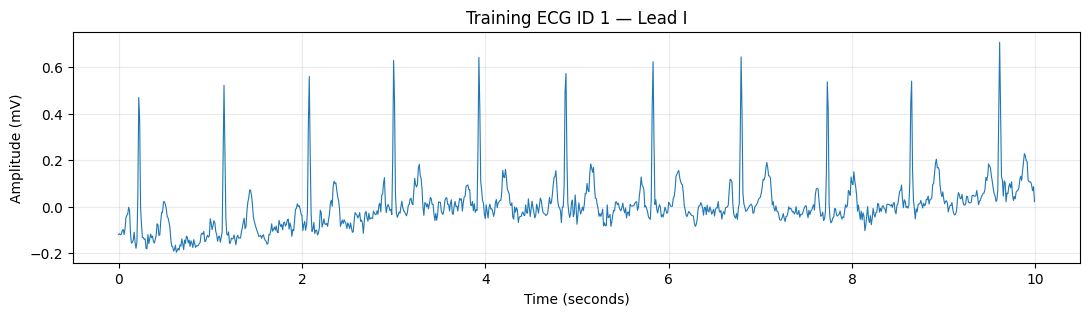

ECG ID: 1
Target vector: [1 0 0 0 0]
Target order: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Positive labels: ['NORM']


In [34]:
# Display one randomly selected training ECG from the loaded sample
sample_index = 0
sample_id = int(ids_train[sample_index])

plt.figure(figsize=(13, 3))
plt.plot(np.arange(1000) / 100.0, X_train[sample_index, 0, :], linewidth=0.8)
plt.title(f"Training ECG ID {sample_id} — Lead I")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True, alpha=0.25)
plt.show()

print("ECG ID:", sample_id)
print("Target vector:", y_train[sample_index].astype(int))
print("Target order:", CLASSES)
print("Positive labels:", [CLASSES[i] for i, v in enumerate(y_train[sample_index]) if v == 1])

## 12. Normalize signals using training statistics only

We calculate a separate mean and standard deviation for each ECG lead using the training sample only. The same values are then applied to validation and test data. This avoids leaking information from validation/test signals into preprocessing.

In [35]:
# X arrays have shape: (records, leads, time)
lead_mean = X_train.mean(axis=(0, 2), keepdims=True).astype(np.float32)
lead_std = X_train.std(axis=(0, 2), keepdims=True).astype(np.float32)
lead_std = np.maximum(lead_std, 1e-6)

X_train_norm = ((X_train - lead_mean) / lead_std).astype(np.float32)
X_val_norm = ((X_val - lead_mean) / lead_std).astype(np.float32)
X_test_norm = ((X_test - lead_mean) / lead_std).astype(np.float32)

print("Mean shape:", lead_mean.shape)
print("Std shape:", lead_std.shape)
print("Normalized training mean (approx):", X_train_norm.mean(axis=(0, 2)).round(3))
print("Normalized training std (approx):", X_train_norm.std(axis=(0, 2)).round(3))

np.save(os.path.join(PROJECT_DIR, "processed", "lead_mean.npy"), lead_mean)
np.save(os.path.join(PROJECT_DIR, "processed", "lead_std.npy"), lead_std)

Mean shape: (1, 12, 1)
Std shape: (1, 12, 1)
Normalized training mean (approx): [ 0. -0. -0.  0. -0. -0.  0. -0. -0. -0.  0. -0.]
Normalized training std (approx): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 13. Build PyTorch data loaders

The input shape expected by `Conv1d` is `(batch, channels, sequence_length)`. For our ECGs this is `(batch, 12, 1000)`. The five target columns are binary multilabel targets.

In [36]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, f1_score

# Reproducibility
TORCH_SEED = RANDOM_STATE
torch.manual_seed(TORCH_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TORCH_SEED)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

train_dataset = TensorDataset(torch.from_numpy(X_train_norm), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val_norm), torch.from_numpy(y_val))
test_dataset = TensorDataset(torch.from_numpy(X_test_norm), torch.from_numpy(y_test))

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training device: cuda
Train batches: 267
Validation batches: 34
Test batches: 34


## 14. Define a lightweight 1D CNN multilabel classifier

This is our first deep-learning baseline. It is not the final selected model. The network uses three 1D convolution blocks, batch normalization, ReLU, max pooling and global average pooling. The final layer outputs five logits. We use `BCEWithLogitsLoss` for multilabel classification.

In [37]:
class ECG_CNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = ECG_CNN(num_classes=len(CLASSES)).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False

## 15. Train with early stopping

Because the default sample is deliberately small, train for a maximum of 15 epochs and use validation loss for early stopping. This is a pipeline demonstration only; do not report its scores as final research results.

In [38]:
MAX_EPOCHS = 15
PATIENCE = 4

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    train_running = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_running += loss.item() * xb.size(0)

    train_loss = train_running / len(train_dataset)

    model.eval()
    val_running = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            val_running += loss.item() * xb.size(0)

    val_loss = val_running / len(val_dataset)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

model.load_state_dict(best_state)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 01/15 | train_loss=0.3957 | val_loss=0.3403
Epoch 02/15 | train_loss=0.3282 | val_loss=0.3275
Epoch 03/15 | train_loss=0.3119 | val_loss=0.3073
Epoch 04/15 | train_loss=0.3025 | val_loss=0.3163
Epoch 05/15 | train_loss=0.2967 | val_loss=0.3005
Epoch 06/15 | train_loss=0.2909 | val_loss=0.3048
Epoch 07/15 | train_loss=0.2862 | val_loss=0.3082
Epoch 08/15 | train_loss=0.2820 | val_loss=0.2979
Epoch 09/15 | train_loss=0.2781 | val_loss=0.2961
Epoch 10/15 | train_loss=0.2763 | val_loss=0.2918
Epoch 11/15 | train_loss=0.2733 | val_loss=0.2939
Epoch 12/15 | train_loss=0.2716 | val_loss=0.2873
Epoch 13/15 | train_loss=0.2694 | val_loss=0.2894
Epoch 14/15 | train_loss=0.2679 | val_loss=0.2883
Epoch 15/15 | train_loss=0.2647 | val_loss=0.2880
Best validation loss: 0.2873


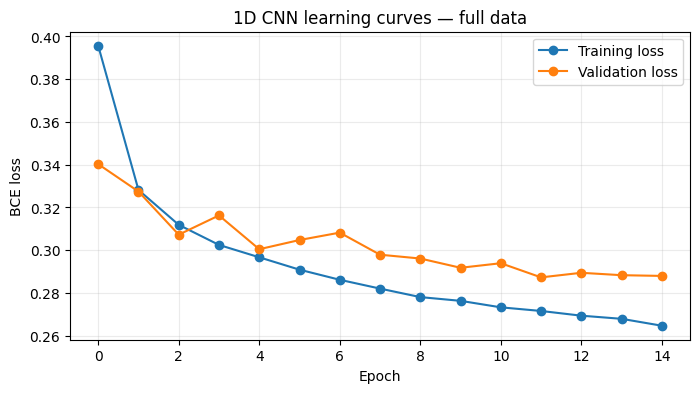

Learning curve saved: /content/drive/MyDrive/ECG_Capstone/plots/cnn_learning_curves_full.png


In [39]:
# Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], marker="o", label="Training loss")
plt.plot(history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("1D CNN learning curves — full data")
plt.legend()
plt.grid(alpha=0.25)

curve_path = os.path.join(PROJECT_DIR, "plots", "cnn_learning_curves_full.png")
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()
print("Learning curve saved:", curve_path)

In [40]:
model.eval()
all_logits, all_targets = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        all_logits.append(model(xb.to(device)).cpu().numpy())
        all_targets.append(yb.numpy())

logits_test = np.concatenate(all_logits, axis=0)
y_true = np.concatenate(all_targets, axis=0).astype(int)
y_prob = 1.0 / (1.0 + np.exp(-logits_test))
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

rows = []
for i, cls in enumerate(CLASSES):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true[:, i], y_pred[:, i], average="binary", zero_division=0)
    rows.append({"Class": cls, "Precision": p, "Recall": r, "F1": f1,
                 "ROC_AUC": roc_auc_score(y_true[:, i], y_prob[:, i]),
                 "Positive test labels": int(y_true[:, i].sum())})

metrics_df = pd.DataFrame(rows)
display(metrics_df.round(3))
print("Full-data macro-F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 3))

,Class,Precision,Recall,F1,ROC_AUC,Positive test labels
0,NORM,0.803,0.883,0.841,0.934,963
1,MI,0.812,0.596,0.688,0.918,550
2,STTC,0.808,0.655,0.723,0.935,521
3,CD,0.879,0.603,0.715,0.908,496
4,HYP,0.720,0.450,0.554,0.888,262


Full-data macro-F1: 0.704


In [41]:
# Inspect a few test predictions
for i in range(min(5, len(ids_test))):
    true_labels = [CLASSES[j] for j in range(len(CLASSES)) if y_true[i, j] == 1]
    predicted_labels = [CLASSES[j] for j in range(len(CLASSES)) if y_pred[i, j] == 1]
    print(f"ECG ID {ids_test[i]}")
    print("  True labels:     ", true_labels)
    print("  Predicted labels:", predicted_labels)
    print("  Scores:          ", np.round(y_prob[i], 3))

ECG ID 9
  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Scores:           [0.938 0.041 0.003 0.067 0.006]
ECG ID 38
  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Scores:           [0.562 0.083 0.008 0.474 0.005]
ECG ID 40
  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Scores:           [0.884 0.015 0.013 0.069 0.026]
ECG ID 57
  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Scores:           [0.988 0.005 0.001 0.009 0.004]
ECG ID 59
  True labels:      ['NORM']
  Predicted labels: ['NORM']
  Scores:           [0.945 0.01  0.011 0.047 0.007]


## 17. Save the model and experiment outputs to Drive

The checkpoint contains model weights, normalization statistics and class order. Save the training history and sample metrics separately.

In [42]:
checkpoint_path = os.path.join(PROJECT_DIR, "models", "ecg_1d_cnn_full.pt")
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": CLASSES,
    "lead_mean": lead_mean,
    "lead_std": lead_std,
    "sampling_rate": 100,
    "input_shape_per_record": [12, 1000],
    "threshold": THRESHOLD,
    "note": "Small-sample pipeline prototype; not for clinical use or final performance claims."
}, checkpoint_path)

metrics_path = os.path.join(PROJECT_DIR, "processed", "cnn_full_test_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)

history_path = os.path.join(PROJECT_DIR, "processed", "cnn_full_training_history.json")
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

print("Model saved:", checkpoint_path)
print("Metrics saved:", metrics_path)
print("History saved:", history_path)

Model saved: /content/drive/MyDrive/ECG_Capstone/models/ecg_1d_cnn_full.pt
Metrics saved: /content/drive/MyDrive/ECG_Capstone/processed/cnn_full_test_metrics.csv
History saved: /content/drive/MyDrive/ECG_Capstone/processed/cnn_full_training_history.json


## 18. Baselines, FFN and model comparison


In [43]:
from scipy.stats import skew, kurtosis
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, f1_score

def tune_thresholds(y_true, y_prob, grid=np.arange(0.05, 0.96, 0.01)):
    """Pick one threshold per class that maximises F1. Use VALIDATION data only."""
    best = []
    for j in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, j], (y_prob[:, j] >= t).astype(int), zero_division=0)
                  for t in grid]
        best.append(float(grid[int(np.argmax(scores))]))
    return np.array(best)

def evaluate(y_true, y_prob, thresholds=0.5):
    y_true = y_true.astype(int)
    thr = np.broadcast_to(np.asarray(thresholds, dtype=float), (y_true.shape[1],))
    y_pred = (y_prob >= thr).astype(int)
    rows = []
    for j, cls in enumerate(CLASSES):
        p, r, f1, _ = precision_recall_fscore_support(
            y_true[:, j], y_pred[:, j], average="binary", zero_division=0)
        rows.append({"Class": cls, "Threshold": round(float(thr[j]), 2), "Precision": p,
                     "Recall": r, "F1": f1,
                     "ROC_AUC": roc_auc_score(y_true[:, j], y_prob[:, j])})
    df = pd.DataFrame(rows)
    return df, df["F1"].mean(), df["ROC_AUC"].mean()

def predict_probs(model, loader):
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.concatenate(out)

def fit(model, train_loader, val_loader, max_epochs=30, patience=5,
        lr=1e-3, weight_decay=1e-4, pos_weight=None):
    """Reusable training loop with early stopping on validation loss."""
    pw = None if pos_weight is None else torch.tensor(pos_weight, dtype=torch.float32, device=device)
    train_criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    val_criterion = nn.BCEWithLogitsLoss()   # same loss for every model, so they compare fairly
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_loss, best_state, wait = float("inf"), copy.deepcopy(model.state_dict()), 0
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(max_epochs):
        model.train()
        run, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = train_criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            run += loss.item() * xb.size(0); n += xb.size(0)
        tr = run / n

        model.eval()
        run, n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                run += val_criterion(model(xb), yb).item() * xb.size(0); n += xb.size(0)
        va = run / n
        history["train_loss"].append(tr); history["val_loss"].append(va)
        print(f"Epoch {epoch+1:02d}/{max_epochs} | train={tr:.4f} | val={va:.4f}")

        if va < best_loss:
            best_loss, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break
    model.load_state_dict(best_state)
    print("Best validation loss:", round(best_loss, 4))
    return model, history

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier

def extract_features(X):
    """9 simple statistics per lead -> 108 features per ECG."""
    d = np.diff(X, axis=2)
    feats = [X.mean(2), X.std(2), X.min(2), X.max(2),
             np.percentile(X, 5, axis=2), np.percentile(X, 95, axis=2),
             np.abs(d).mean(2), skew(X, axis=2), kurtosis(X, axis=2)]
    return np.nan_to_num(np.concatenate(feats, axis=1)).astype(np.float32)

def extract_in_chunks(X, chunk=2000):
    return np.concatenate([extract_features(X[i:i+chunk]) for i in range(0, len(X), chunk)])

F_train = extract_in_chunks(X_train)
F_val = extract_in_chunks(X_val)
F_test = extract_in_chunks(X_test)
print("Feature shapes:", F_train.shape, F_val.shape, F_test.shape)

scaler = StandardScaler().fit(F_train)          # fit on training data only
F_train_s, F_val_s, F_test_s = (scaler.transform(F) for F in (F_train, F_val, F_test))

yi_train = y_train.astype(int)

logreg = OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight="balanced"))
logreg.fit(F_train_s, yi_train)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(F_train, yi_train)

def rf_probs(F):
    return np.stack([p[:, 1] for p in rf.predict_proba(F)], axis=1)

results = {
    "Logistic Regression": (logreg.predict_proba(F_val_s), logreg.predict_proba(F_test_s)),
    "Random Forest": (rf_probs(F_val), rf_probs(F_test)),
}
print("Baselines trained.")

Feature shapes: (17084, 108) (2146, 108) (2158, 108)
Baselines trained.


In [45]:
ffn_train_loader = DataLoader(TensorDataset(torch.from_numpy(F_train_s.astype(np.float32)),
                                            torch.from_numpy(y_train)), batch_size=128, shuffle=True)
ffn_val_loader = DataLoader(TensorDataset(torch.from_numpy(F_val_s.astype(np.float32)),
                                          torch.from_numpy(y_val)), batch_size=256)
ffn_test_loader = DataLoader(TensorDataset(torch.from_numpy(F_test_s.astype(np.float32)),
                                           torch.from_numpy(y_test)), batch_size=256)

class ECG_FFN(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, n_classes))
    def forward(self, x):
        return self.net(x)

torch.manual_seed(RANDOM_STATE)
ffn = ECG_FFN(F_train_s.shape[1], len(CLASSES)).to(device)
ffn, ffn_history = fit(ffn, ffn_train_loader, ffn_val_loader, max_epochs=50, patience=7)

results["FFN"] = (predict_probs(ffn, ffn_val_loader), predict_probs(ffn, ffn_test_loader))

Epoch 01/50 | train=0.4428 | val=0.3800
Epoch 02/50 | train=0.3777 | val=0.3633
Epoch 03/50 | train=0.3650 | val=0.3591
Epoch 04/50 | train=0.3573 | val=0.3546
Epoch 05/50 | train=0.3530 | val=0.3550
Epoch 06/50 | train=0.3486 | val=0.3498
Epoch 07/50 | train=0.3445 | val=0.3492
Epoch 08/50 | train=0.3432 | val=0.3475
Epoch 09/50 | train=0.3387 | val=0.3463
Epoch 10/50 | train=0.3355 | val=0.3450
Epoch 11/50 | train=0.3344 | val=0.3476
Epoch 12/50 | train=0.3320 | val=0.3451
Epoch 13/50 | train=0.3318 | val=0.3433
Epoch 14/50 | train=0.3297 | val=0.3440
Epoch 15/50 | train=0.3266 | val=0.3462
Epoch 16/50 | train=0.3263 | val=0.3437
Epoch 17/50 | train=0.3270 | val=0.3399
Epoch 18/50 | train=0.3228 | val=0.3431
Epoch 19/50 | train=0.3230 | val=0.3395
Epoch 20/50 | train=0.3209 | val=0.3410
Epoch 21/50 | train=0.3199 | val=0.3437
Epoch 22/50 | train=0.3186 | val=0.3404
Epoch 23/50 | train=0.3179 | val=0.3429
Epoch 24/50 | train=0.3157 | val=0.3402
Epoch 25/50 | train=0.3168 | val=0.3428


In [46]:
# CNN probabilities (the trained model and loaders from earlier cells)
results["1D CNN"] = (predict_probs(model, val_loader), predict_probs(model, test_loader))

rows, tuned_thresholds = [], {}
for name, (p_val, p_test) in results.items():
    thr = tune_thresholds(y_val, p_val)          # thresholds chosen on validation only
    tuned_thresholds[name] = thr
    _, f1_default, auc = evaluate(y_test, p_test, 0.5)
    _, f1_tuned, _ = evaluate(y_test, p_test, thr)
    rows.append({"Model": name,
                 "Macro-F1 (thr 0.5)": f1_default,
                 "Macro-F1 (tuned thr)": f1_tuned,
                 "Macro ROC-AUC": auc})

comparison = pd.DataFrame(rows).round(3)
display(comparison)

cnn_table, _, _ = evaluate(y_test, results["1D CNN"][1], tuned_thresholds["1D CNN"])
print("\n1D CNN per-class results with validation-tuned thresholds:")
display(cnn_table.round(3))

comparison.to_csv(os.path.join(PROJECT_DIR, "processed", "model_comparison.csv"), index=False)
np.savez(os.path.join(PROJECT_DIR, "processed", "probabilities_step2.npz"),
         **{f"{k}_{s}".replace(" ", "_"): v[i] for k, v in results.items()
            for i, s in enumerate(["val", "test"])})

,Model,Macro-F1 (thr 0.5),Macro-F1 (tuned thr),Macro ROC-AUC
0,Logistic Regression,0.596,0.608,0.827
1,Random Forest,0.529,0.647,0.857
2,FFN,0.632,0.654,0.871
3,1D CNN,0.704,0.730,0.917



1D CNN per-class results with validation-tuned thresholds:


,Class,Threshold,Precision,Recall,F1,ROC_AUC
0,NORM,0.39,0.775,0.928,0.845,0.934
1,MI,0.28,0.690,0.762,0.724,0.918
2,STTC,0.35,0.747,0.789,0.768,0.935
3,CD,0.42,0.839,0.653,0.735,0.908
4,HYP,0.24,0.525,0.645,0.579,0.888


In [47]:
class ECG_Recurrent(nn.Module):
    """Simple RNN / LSTM / GRU on the ECG, downsampled 1000 -> 250 steps."""
    def __init__(self, kind="LSTM", hidden=64, n_classes=5, downsample=4):
        super().__init__()
        self.pool = nn.AvgPool1d(downsample)
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = rnn_cls(input_size=12, hidden_size=hidden, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):
        x = self.pool(x).transpose(1, 2)      # (batch, 250, 12)
        out, _ = self.rnn(x)
        return self.fc(self.drop(out[:, -1, :]))

class ECG_CNN_BiLSTM(nn.Module):
    """Your proposed main model: CNN features -> BiLSTM -> dense output."""
    def __init__(self, n_classes=5, hidden=64):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(12, 32, 7, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 3, padding=1), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2))
        self.lstm = nn.LSTM(128, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):
        x = self.cnn(x).transpose(1, 2)       # (batch, 125, 128)
        out, _ = self.lstm(x)
        return self.fc(self.drop(out.mean(dim=1)))

In [48]:
pos = y_train.sum(axis=0)
pos_weight = ((len(y_train) - pos) / pos).astype(np.float32)
print("pos_weight per class:", pos_weight.round(2))

experiments = {
    "1D CNN + pos_weight": lambda: ECG_CNN(num_classes=len(CLASSES)),
    "Simple RNN":          lambda: ECG_Recurrent("RNN"),
    "LSTM":                lambda: ECG_Recurrent("LSTM"),
    "GRU":                 lambda: ECG_Recurrent("GRU"),
    "CNN-BiLSTM":          lambda: ECG_CNN_BiLSTM(),
}

histories = {}
for name, make in experiments.items():
    print(f"\n===== {name} =====")
    torch.manual_seed(RANDOM_STATE)
    m = make().to(device)
    pw = pos_weight if "pos_weight" in name else None
    m, histories[name] = fit(m, train_loader, val_loader,
                             max_epochs=30, patience=5, pos_weight=pw)
    results[name] = (predict_probs(m, val_loader), predict_probs(m, test_loader))
    fname = name.replace(" ", "_").replace("+", "plus") + ".pt"
    torch.save(m.state_dict(), os.path.join(PROJECT_DIR, "models", fname))

pos_weight per class: [1.25 2.9  3.08 3.37 7.06]

===== 1D CNN + pos_weight =====
Epoch 01/30 | train=0.7260 | val=0.4093
Epoch 02/30 | train=0.6194 | val=0.3947
Epoch 03/30 | train=0.5878 | val=0.3831
Epoch 04/30 | train=0.5715 | val=0.3591
Epoch 05/30 | train=0.5590 | val=0.3755
Epoch 06/30 | train=0.5478 | val=0.3664
Epoch 07/30 | train=0.5391 | val=0.3820
Epoch 08/30 | train=0.5294 | val=0.3468
Epoch 09/30 | train=0.5216 | val=0.3888
Epoch 10/30 | train=0.5177 | val=0.3995
Epoch 11/30 | train=0.5138 | val=0.3835
Epoch 12/30 | train=0.5076 | val=0.3590
Epoch 13/30 | train=0.5042 | val=0.3395
Epoch 14/30 | train=0.5010 | val=0.3523
Epoch 15/30 | train=0.4961 | val=0.3510
Epoch 16/30 | train=0.4912 | val=0.3483
Epoch 17/30 | train=0.4897 | val=0.3471
Epoch 18/30 | train=0.4855 | val=0.3454
Early stopping.
Best validation loss: 0.3395

===== Simple RNN =====
Epoch 01/30 | train=0.5515 | val=0.5381
Epoch 02/30 | train=0.5314 | val=0.5205
Epoch 03/30 | train=0.5096 | val=0.4870
Epoch 04/

In [49]:
rows, tuned_thresholds = [], {}
for name, (p_val, p_test) in results.items():
    thr = tune_thresholds(y_val, p_val)              # thresholds tuned on validation only
    tuned_thresholds[name] = thr
    _, _, auc_val = evaluate(y_val, p_val, thr)
    _, f1_default, auc_test = evaluate(y_test, p_test, 0.5)
    _, f1_tuned, _ = evaluate(y_test, p_test, thr)
    rows.append({"Model": name,
                 "Val macro-AUC": auc_val,
                 "Test macro-F1 (thr 0.5)": f1_default,
                 "Test macro-F1 (tuned thr)": f1_tuned,
                 "Test macro-AUC": auc_test})

comparison = pd.DataFrame(rows).sort_values("Val macro-AUC", ascending=False).round(3)
display(comparison)

best_name = comparison.iloc[0]["Model"]
best_table, _, _ = evaluate(y_test, results[best_name][1], tuned_thresholds[best_name])
print(f"\nBest model by validation AUC: {best_name}")
display(best_table.round(3))

comparison.to_csv(os.path.join(PROJECT_DIR, "processed", "model_comparison.csv"), index=False)
np.savez(os.path.join(PROJECT_DIR, "processed", "probabilities_step2.npz"),
         **{f"{k}_{s}".replace(" ", "_"): v[i] for k, v in results.items()
            for i, s in enumerate(["val", "test"])})

,Model,Val macro-AUC,Test macro-F1 (thr 0.5),Test macro-F1 (tuned thr),Test macro-AUC
8,CNN-BiLSTM,0.932,0.725,0.748,0.927
3,1D CNN,0.921,0.704,0.730,0.917
4,1D CNN + pos_weight,0.919,0.720,0.728,0.913
7,GRU,0.903,0.683,0.701,0.897
6,LSTM,0.886,0.640,0.681,0.880
2,FFN,0.886,0.632,0.654,0.871
1,Random Forest,0.873,0.529,0.647,0.857
0,Logistic Regression,0.845,0.596,0.608,0.827
5,Simple RNN,0.775,0.328,0.555,0.770



Best model by validation AUC: CNN-BiLSTM


,Class,Threshold,Precision,Recall,F1,ROC_AUC
0,NORM,0.47,0.810,0.918,0.860,0.949
1,MI,0.42,0.752,0.749,0.750,0.932
2,STTC,0.22,0.730,0.845,0.783,0.938
3,CD,0.34,0.810,0.720,0.762,0.917
4,HYP,0.43,0.653,0.531,0.585,0.900


In [50]:
final_name = "CNN-BiLSTM"
final_thr = tuned_thresholds[final_name]
with open(os.path.join(PROJECT_DIR, "processed", "final_model_thresholds.json"), "w") as f:
    json.dump({"model": final_name, "classes": CLASSES,
               "thresholds": [float(t) for t in final_thr]}, f, indent=2)
print("Saved thresholds:", dict(zip(CLASSES, np.round(final_thr, 2))))

Saved thresholds: {'NORM': np.float64(0.47), 'MI': np.float64(0.42), 'STTC': np.float64(0.22), 'CD': np.float64(0.34), 'HYP': np.float64(0.43)}


shared helpers and PCA


Downsampled signal matrix: (17084, 2400) (12 leads x 200 samples)

PCA variance retained:
  80% of variance needs more than 100 components
  90% of variance needs more than 100 components
  95% of variance needs more than 100 components
  99% of variance needs more than 100 components
  k= 10: variance=0.189, validation reconstruction MSE=0.6017
  k= 50: variance=0.364, validation reconstruction MSE=0.4876
  k=100: variance=0.495, validation reconstruction MSE=0.4017
PCA (10 components): 10 features | val AUC=0.498 | test AUC=0.495
PCA (50 components): 50 features | val AUC=0.509 | test AUC=0.499
PCA (100 components): 100 features | val AUC=0.508 | test AUC=0.491


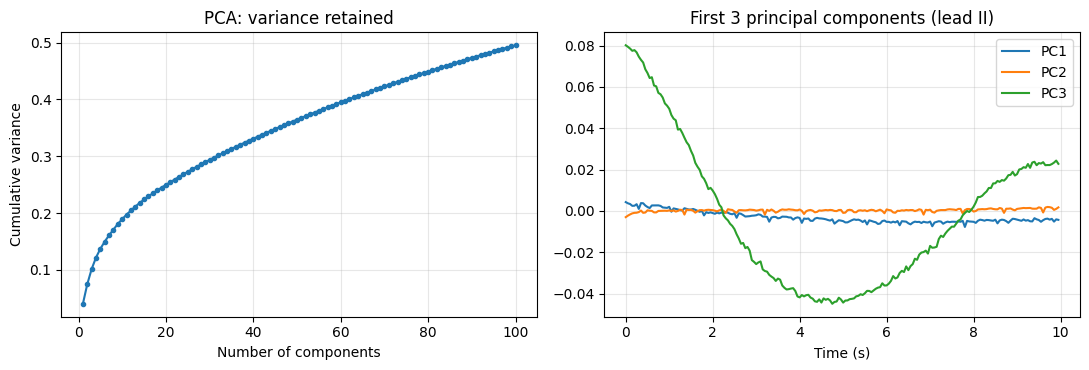

In [51]:
from sklearn.decomposition import PCA, FactorAnalysis, FastICA
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
rep_rows = []   # one summary row per representation

def macro_auc(y_true, y_prob):
    return float(np.mean([roc_auc_score(y_true[:, j].astype(int), y_prob[:, j])
                          for j in range(y_true.shape[1])]))

def eval_representation(name, Z_train, Z_val, Z_test):
    """Logistic Regression on a learned representation -> macro ROC-AUC on val and test."""
    sc = StandardScaler().fit(Z_train)
    clf = OneVsRestClassifier(LogisticRegression(max_iter=3000, class_weight="balanced"))
    clf.fit(sc.transform(Z_train), y_train.astype(int))
    auc_val = macro_auc(y_val, clf.predict_proba(sc.transform(Z_val)))
    auc_test = macro_auc(y_test, clf.predict_proba(sc.transform(Z_test)))
    rep_rows.append({"Representation": name, "Features": Z_train.shape[1],
                     "Val macro-AUC": round(auc_val, 3), "Test macro-AUC": round(auc_test, 3)})
    print(f"{name}: {Z_train.shape[1]} features | val AUC={auc_val:.3f} | test AUC={auc_test:.3f}")

def downsample(X, factor=5):
    n, l, t = X.shape
    return X.reshape(n, l, t // factor, factor).mean(axis=3)

D_train = downsample(X_train_norm).reshape(len(X_train_norm), -1)
D_val = downsample(X_val_norm).reshape(len(X_val_norm), -1)
D_test = downsample(X_test_norm).reshape(len(X_test_norm), -1)
print("Downsampled signal matrix:", D_train.shape, "(12 leads x 200 samples)")

# ---------------- PCA ----------------
N_PCA = min(100, D_train.shape[0] - 1)
pca = PCA(n_components=N_PCA, svd_solver="randomized", random_state=RANDOM_STATE).fit(D_train)
cum = np.cumsum(pca.explained_variance_ratio_)
print("\nPCA variance retained:")
for target in (0.80, 0.90, 0.95, 0.99):
    if cum[-1] >= target:
        print(f"  {int(target*100)}% of variance needs {int(np.searchsorted(cum, target)) + 1} components")
    else:
        print(f"  {int(target*100)}% of variance needs more than {N_PCA} components")

for k in (10, 50, N_PCA):
    Zk = pca.transform(D_val)[:, :k]
    recon = Zk @ pca.components_[:k] + pca.mean_
    mse = float(np.mean((D_val - recon) ** 2))
    print(f"  k={k:3d}: variance={cum[k-1]:.3f}, validation reconstruction MSE={mse:.4f}")

P_train, P_val, P_test = (pca.transform(D) for D in (D_train, D_val, D_test))
for k in (10, 50, N_PCA):
    eval_representation(f"PCA ({k} components)", P_train[:, :k], P_val[:, :k], P_test[:, :k])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(np.arange(1, N_PCA + 1), cum, marker=".")
ax[0].set_xlabel("Number of components"); ax[0].set_ylabel("Cumulative variance")
ax[0].set_title("PCA: variance retained"); ax[0].grid(alpha=0.3)
t_axis = np.arange(200) / 20.0
for c in range(3):
    ax[1].plot(t_axis, pca.components_[c].reshape(12, 200)[1], label=f"PC{c+1}")
ax[1].set_title("First 3 principal components (lead II)")
ax[1].set_xlabel("Time (s)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "plots", "pca_variance_components.png"), dpi=150, bbox_inches="tight")
plt.show()

Factor Analysis and ICA

In [52]:
# ---------------- Factor Analysis (on the 108 summary features from Step 2) ----------------
stat_names = ["mean", "std", "min", "max", "p5", "p95", "mean|diff|", "skew", "kurtosis"]
feature_names = [f"{s}_{l}" for s in stat_names for l in LEADS]   # same order as extract_features

print("Factor Analysis: validation log-likelihood by number of factors")
fa_models = {}
for k in (5, 10, 20):
    fa_k = FactorAnalysis(n_components=k, random_state=RANDOM_STATE).fit(F_train_s)
    fa_models[k] = fa_k
    print(f"  {k:2d} factors: val avg log-likelihood = {fa_k.score(F_val_s):.3f}")
best_k = max(fa_models, key=lambda k: fa_models[k].score(F_val_s))
fa = fa_models[best_k]
print("Chosen number of factors:", best_k)

print("\nTop loadings for the first 4 factors:")
for f_idx in range(4):
    load = fa.components_[f_idx]
    top = np.argsort(-np.abs(load))[:5]
    print(f"  Factor {f_idx+1}:", ", ".join(f"{feature_names[i]} ({load[i]:+.2f})" for i in top))

eval_representation(f"Factor Analysis ({best_k} factors)",
                    fa.transform(F_train_s), fa.transform(F_val_s), fa.transform(F_test_s))

# ---------------- ICA (on the first 30 PCA scores of the waveforms) ----------------
N_ICA = min(20, N_PCA)
ica = FastICA(n_components=N_ICA, whiten="unit-variance", max_iter=1000, tol=1e-3,
              random_state=RANDOM_STATE)
S_train = ica.fit_transform(P_train[:, :30])
S_val, S_test = ica.transform(P_val[:, :30]), ica.transform(P_test[:, :30])

from scipy.stats import kurtosis as sp_kurtosis
ic_kurt = sp_kurtosis(S_train, axis=0)
print("\nICA: excess kurtosis of each independent component (0 = Gaussian):")
print(np.round(np.sort(np.abs(ic_kurt))[::-1], 2))
eval_representation(f"ICA ({N_ICA} components)", S_train, S_val, S_test)

Factor Analysis: validation log-likelihood by number of factors
   5 factors: val avg log-likelihood = -281.826
  10 factors: val avg log-likelihood = -263.154
  20 factors: val avg log-likelihood = -805.767
Chosen number of factors: 10

Top loadings for the first 4 factors:
  Factor 1: mean_aVL (-1.00), mean_III (+0.96), mean_I (-0.96), mean_aVF (+0.79), mean_aVR (+0.73)
  Factor 2: std_III (+0.93), std_aVF (+0.89), std_aVL (+0.83), p5_aVF (-0.78), p5_III (-0.77)
  Factor 3: skew_III (-0.82), max_aVF (-0.78), max_II (-0.75), skew_aVF (-0.74), max_aVL (+0.71)
  Factor 4: min_aVR (-0.84), max_I (+0.69), std_aVR (+0.69), mean|diff|_aVR (+0.63), skew_aVR (-0.58)
Factor Analysis (10 factors): 10 features | val AUC=0.759 | test AUC=0.745

ICA: excess kurtosis of each independent component (0 = Gaussian):
[8664.18 4930.68 4078.42 1644.34  183.1   165.18  158.63  154.45   86.66
   84.63   63.47   55.29   52.81   49.56   35.3    34.61   28.49   25.33
   22.11    8.71]
ICA (20 components): 20 f

###Slow Feature Analysis


SFA slowness values (smaller = slower), slowest first:
[0.0248 0.0982 0.1055 0.1744 0.1938 0.2383 0.3188 0.5128 1.2588 1.5975
 1.647  1.8189]
SFA (12 slow features, 3 stats each): 36 features | val AUC=0.768 | test AUC=0.750


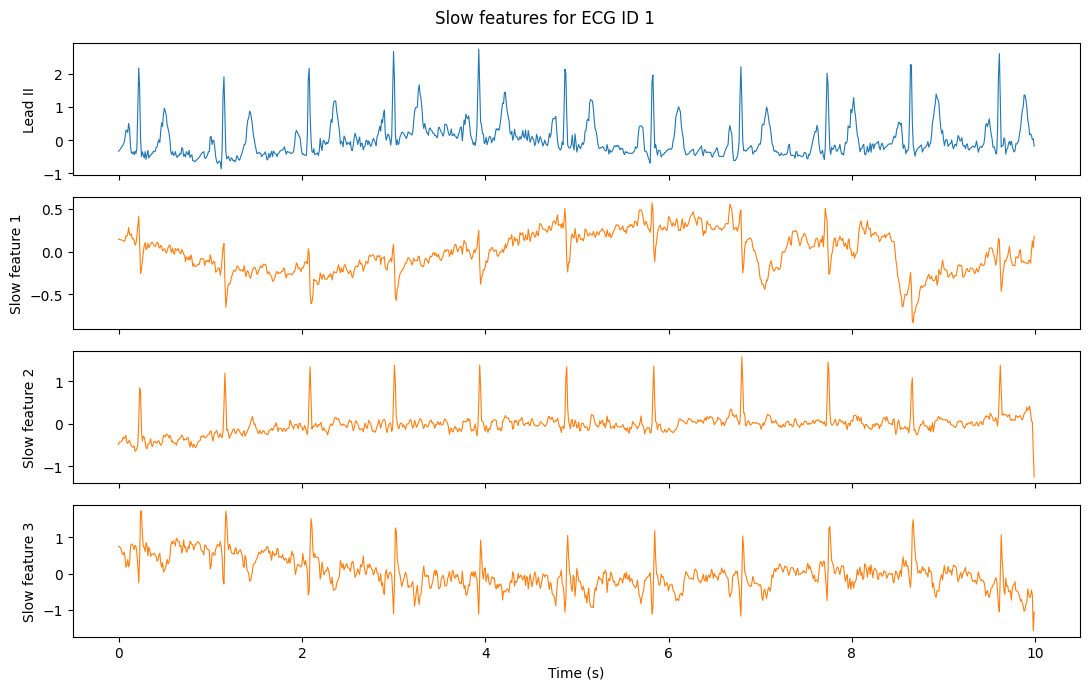

In [53]:
from scipy.linalg import eigh

def fit_sfa(X, chunk=1000):
    """Find linear combinations of the 12 leads that change as slowly as possible over time."""
    C = np.zeros((12, 12)); Cd = np.zeros((12, 12)); n_x = 0; n_d = 0
    for i in range(0, len(X), chunk):
        xb = X[i:i + chunk].astype(np.float64)
        a = xb.transpose(0, 2, 1).reshape(-1, 12)
        b = np.diff(xb, axis=2).transpose(0, 2, 1).reshape(-1, 12)
        C += a.T @ a; Cd += b.T @ b; n_x += len(a); n_d += len(b)
    C /= n_x; Cd /= n_d
    eigvals, W = eigh(Cd, C)       # smallest eigenvalue = slowest feature
    return eigvals, W

sfa_eigvals, sfa_W = fit_sfa(X_train_norm)     # fitted on training data only
print("SFA slowness values (smaller = slower), slowest first:")
print(np.round(sfa_eigvals, 4))

def sfa_features(X, W, chunk=1000):
    out = []
    for i in range(0, len(X), chunk):
        Y = np.einsum("lk,nlt->nkt", W, X[i:i + chunk].astype(np.float64))
        out.append(np.concatenate([Y.std(axis=2), np.abs(Y).max(axis=2), Y.mean(axis=2)], axis=1))
    return np.concatenate(out).astype(np.float32)

SF_train = sfa_features(X_train_norm, sfa_W)
SF_val = sfa_features(X_val_norm, sfa_W)
SF_test = sfa_features(X_test_norm, sfa_W)
eval_representation("SFA (12 slow features, 3 stats each)", SF_train, SF_val, SF_test)

idx = 0
Y_one = np.einsum("lk,lt->kt", sfa_W, X_train_norm[idx].astype(np.float64))
t_full = np.arange(1000) / 100.0
fig, ax = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t_full, X_train_norm[idx, 1], lw=0.8); ax[0].set_ylabel("Lead II")
for k in range(3):
    ax[k + 1].plot(t_full, Y_one[k], lw=0.8, color="tab:orange")
    ax[k + 1].set_ylabel(f"Slow feature {k+1}")
ax[3].set_xlabel("Time (s)")
fig.suptitle(f"Slow features for ECG ID {int(ids_train[idx])}")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "plots", "sfa_slow_features.png"), dpi=150, bbox_inches="tight")
plt.show()

### Hidden Markov Model


Gaussian HMM: held-out log-likelihood per time step
  3 states: validation log-likelihood per step = -9.231
  4 states: validation log-likelihood per step = -8.526
  6 states: validation log-likelihood per step = -7.978
Chosen number of hidden states: 6
Transition matrix:
 [[0.03  0.006 0.734 0.082 0.011 0.137]
 [0.006 0.617 0.003 0.125 0.239 0.01 ]
 [0.986 0.    0.    0.003 0.009 0.002]
 [0.019 0.026 0.024 0.83  0.05  0.051]
 [0.007 0.081 0.007 0.058 0.758 0.089]
 [0.099 0.018 0.017 0.037 0.058 0.772]]
HMM (6 states: occupancy + transitions): 42 features | val AUC=0.780 | test AUC=0.772

Average fraction of time in each hidden state, by class (test set):


,State 0,State 1,State 2,State 3,State 4,State 5
NORM,0.131,0.060,0.109,0.307,0.210,0.183
MI,0.114,0.079,0.091,0.204,0.230,0.282
STTC,0.106,0.082,0.085,0.237,0.227,0.263
CD,0.103,0.098,0.081,0.190,0.261,0.266
HYP,0.085,0.100,0.066,0.266,0.262,0.221


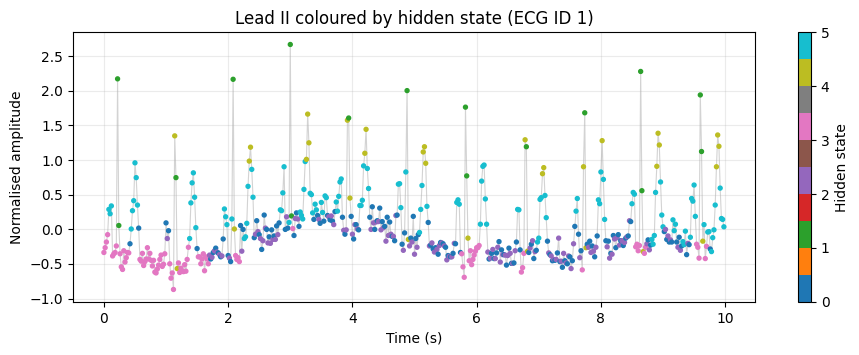

In [54]:
import subprocess, sys
try:
    from hmmlearn import hmm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "hmmlearn"], check=True)
    from hmmlearn import hmm

def to_sequences(X, step=2):
    Xs = X[:, :, ::step]
    n, _, t = Xs.shape
    return Xs.transpose(0, 2, 1).reshape(-1, 12).astype(np.float64), [t] * n

rng_h = np.random.default_rng(RANDOM_STATE)
N_FIT = min(800, len(X_train_norm))
fit_idx = rng_h.choice(len(X_train_norm), size=N_FIT, replace=False)
obs_fit, len_fit = to_sequences(X_train_norm[fit_idx])
obs_val_h, len_val_h = to_sequences(X_val_norm[:300])

hmm_models = {}
print("Gaussian HMM: held-out log-likelihood per time step")
for n_states in (3, 4, 6):
    m = hmm.GaussianHMM(n_components=n_states, covariance_type="diag",
                        n_iter=25, tol=1e-3, random_state=RANDOM_STATE)
    m.fit(obs_fit, len_fit)
    hmm_models[n_states] = m
    ll = m.score(obs_val_h, len_val_h) / len(obs_val_h)
    print(f"  {n_states} states: validation log-likelihood per step = {ll:.3f}")

best_states = max(hmm_models, key=lambda s: hmm_models[s].score(obs_val_h, len_val_h))
hmm_model = hmm_models[best_states]
print("Chosen number of hidden states:", best_states)
print("Transition matrix:\n", np.round(hmm_model.transmat_, 3))

def hmm_features(X, model, chunk=500):
    k = model.n_components
    feats = []
    for i in range(0, len(X), chunk):
        obs, lens = to_sequences(X[i:i + chunk])
        states = model.predict(obs, lens)
        pos = 0
        for L in lens:
            s = states[pos:pos + L]; pos += L
            occ = np.bincount(s, minlength=k) / L
            trans = np.zeros((k, k))
            np.add.at(trans, (s[:-1], s[1:]), 1)
            feats.append(np.concatenate([occ, (trans / (L - 1)).ravel()]))
    return np.asarray(feats, dtype=np.float32)

H_train = hmm_features(X_train_norm, hmm_model)
H_val = hmm_features(X_val_norm, hmm_model)
H_test = hmm_features(X_test_norm, hmm_model)
eval_representation(f"HMM ({best_states} states: occupancy + transitions)", H_train, H_val, H_test)

occ_rows = {}
for j, cls in enumerate(CLASSES):
    occ_rows[cls] = H_test[y_test[:, j] == 1, :best_states].mean(axis=0)
occ_df = pd.DataFrame(occ_rows, index=[f"State {s}" for s in range(best_states)]).T
print("\nAverage fraction of time in each hidden state, by class (test set):")
display(occ_df.round(3))

obs_one, len_one = to_sequences(X_train_norm[:1])
states_one = hmm_model.predict(obs_one, len_one)
t_half = np.arange(len(states_one)) / 50.0
plt.figure(figsize=(11, 3.5))
plt.plot(t_half, obs_one[:, 1], color="lightgray", lw=0.8, zorder=1)
sc = plt.scatter(t_half, obs_one[:, 1], c=states_one, cmap="tab10", s=8, zorder=2)
plt.title(f"Lead II coloured by hidden state (ECG ID {int(ids_train[0])})")
plt.xlabel("Time (s)"); plt.ylabel("Normalised amplitude"); plt.grid(alpha=0.25)
plt.colorbar(sc, label="Hidden state")
plt.savefig(os.path.join(PROJECT_DIR, "plots", "hmm_states_example.png"), dpi=150, bbox_inches="tight")
plt.show()

###: summary table

In [55]:
ref_lr = macro_auc(y_test, results["Logistic Regression"][1])
ref_cnn = macro_auc(y_test, results["CNN-BiLSTM"][1])
summary = pd.DataFrame(rep_rows)
summary.loc[len(summary)] = ["Reference: LR on 108 summary features (Step 2)", 108, np.nan, round(ref_lr, 3)]
summary.loc[len(summary)] = ["Reference: CNN-BiLSTM (end-to-end)", np.nan, np.nan, round(ref_cnn, 3)]
display(summary)
summary.to_csv(os.path.join(PROJECT_DIR, "processed", "representation_comparison.csv"), index=False)

,Representation,Features,Val macro-AUC,Test macro-AUC
0,PCA (10 components),10.0,0.498,0.495
1,PCA (50 components),50.0,0.509,0.499
2,PCA (100 components),100.0,0.508,0.491
3,Factor Analysis (10 factors),10.0,0.759,0.745
4,ICA (20 components),20.0,0.500,0.494
5,"SFA (12 slow features, 3 stats each)",36.0,0.768,0.750
6,HMM (6 states: occupancy + transitions),42.0,0.780,0.772
7,Reference: LR on 108 summary features (Step 2),108.0,NaN,0.827
8,Reference: CNN-BiLSTM (end-to-end),NaN,NaN,0.927


In [56]:
# Diagnostic: are a few extreme recordings dominating PCA / ICA?
rec_rms = np.sqrt((D_train ** 2).mean(axis=1))
print("RMS amplitude per recording, percentiles 50/90/99/99.9/100:",
      np.round(np.percentile(rec_rms, [50, 90, 99, 99.9, 100]), 2))
print("Max |value| per recording, percentiles 50/90/99/100:",
      np.round(np.percentile(np.abs(D_train).max(axis=1), [50, 90, 99, 100]), 1))
top = np.argsort(-rec_rms)[:max(1, int(0.01 * len(rec_rms)))]
share = float((D_train[top] ** 2).sum() / (D_train ** 2).sum())
print(f"Share of total signal energy held by the top 1% of recordings: {share:.3f} (about 0.01 if evenly spread)")

# Robust version: clip extreme values (in standard-deviation units), then refit PCA and ICA
CLIP = 5.0
Dc_train, Dc_val, Dc_test = (np.clip(D, -CLIP, CLIP) for D in (D_train, D_val, D_test))
pca_c = PCA(n_components=N_PCA, svd_solver="randomized", random_state=RANDOM_STATE).fit(Dc_train)
cum_c = np.cumsum(pca_c.explained_variance_ratio_)
print(f"\nClipped PCA: {N_PCA} components keep {cum_c[-1]:.3f} of the variance "
      f"(unclipped: {cum[-1]:.3f})")
Pc_train, Pc_val, Pc_test = (pca_c.transform(D) for D in (Dc_train, Dc_val, Dc_test))
for k in (10, 50, N_PCA):
    eval_representation(f"PCA clipped ({k} components)", Pc_train[:, :k], Pc_val[:, :k], Pc_test[:, :k])

ica_c = FastICA(n_components=N_ICA, whiten="unit-variance", max_iter=1000, tol=1e-3,
                random_state=RANDOM_STATE)
Sc_train = ica_c.fit_transform(Pc_train[:, :30])
Sc_val, Sc_test = ica_c.transform(Pc_val[:, :30]), ica_c.transform(Pc_test[:, :30])
print("\nClipped ICA: excess kurtosis per component:",
      np.round(np.sort(np.abs(sp_kurtosis(Sc_train, axis=0)))[::-1], 1))
eval_representation(f"ICA clipped ({N_ICA} components)", Sc_train, Sc_val, Sc_test)

RMS amplitude per recording, percentiles 50/90/99/99.9/100: [ 0.63  1.1   2.06  3.47 20.16]
Max |value| per recording, percentiles 50/90/99/100: [ 3.7  7.6 15.5 71.3]
Share of total signal energy held by the top 1% of recordings: 0.180 (about 0.01 if evenly spread)

Clipped PCA: 100 components keep 0.454 of the variance (unclipped: 0.495)
PCA clipped (10 components): 10 features | val AUC=0.512 | test AUC=0.514
PCA clipped (50 components): 50 features | val AUC=0.526 | test AUC=0.520
PCA clipped (100 components): 100 features | val AUC=0.527 | test AUC=0.514

Clipped ICA: excess kurtosis per component: [1274.3 1151.7   58.5   45.7   42.8   42.    40.2   38.9   31.4   25.9
   25.2   24.9   23.3   21.8   20.3   19.7    9.6    7.9    7.3    6.6]
ICA clipped (20 components): 20 features | val AUC=0.526 | test AUC=0.524


### PCA and ICA on the summary features


In [57]:
# PCA and ICA on the 108 summary features (the same input Factor Analysis used)
N_PCA_F = min(60, F_train_s.shape[1])
pca_f = PCA(n_components=N_PCA_F, random_state=RANDOM_STATE).fit(F_train_s)
cum_f = np.cumsum(pca_f.explained_variance_ratio_)
print("PCA on summary features, variance retained:")
for target in (0.80, 0.90, 0.95):
    if cum_f[-1] >= target:
        print(f"  {int(target*100)}% needs {int(np.searchsorted(cum_f, target)) + 1} components")
    else:
        print(f"  {int(target*100)}% needs more than {N_PCA_F} components")

Pf_train, Pf_val, Pf_test = (pca_f.transform(F) for F in (F_train_s, F_val_s, F_test_s))
for k in (10, 20, 30):
    eval_representation(f"PCA on summary features ({k} components)",
                        Pf_train[:, :k], Pf_val[:, :k], Pf_test[:, :k])

ica_f = FastICA(n_components=10, whiten="unit-variance", max_iter=1000, tol=1e-3,
                random_state=RANDOM_STATE)
Sf_train = ica_f.fit_transform(Pf_train[:, :20])
Sf_val, Sf_test = ica_f.transform(Pf_val[:, :20]), ica_f.transform(Pf_test[:, :20])
print("\nICA on summary features, excess kurtosis:",
      np.round(np.sort(np.abs(sp_kurtosis(Sf_train, axis=0)))[::-1], 1))
eval_representation("ICA on summary features (10 components)", Sf_train, Sf_val, Sf_test)

PCA on summary features, variance retained:
  80% needs 17 components
  90% needs 27 components
  95% needs 39 components
PCA on summary features (10 components): 10 features | val AUC=0.776 | test AUC=0.760
PCA on summary features (20 components): 20 features | val AUC=0.800 | test AUC=0.782
PCA on summary features (30 components): 30 features | val AUC=0.810 | test AUC=0.796

ICA on summary features, excess kurtosis: [3.6473e+03 3.3168e+03 6.8500e+01 1.6500e+01 1.0400e+01 4.8000e+00
 4.3000e+00 3.6000e+00 1.9000e+00 1.2000e+00]
ICA on summary features (10 components): 10 features | val AUC=0.776 | test AUC=0.760


###Save the artifact-heavy recordings for later
These recordings are a data-quality issue, and your capstone asks for failure and robustness analysis. This cell flags the top 1% by amplitude, so you can later check whether the CNN-BiLSTM does worse on them:

In [58]:
def max_abs(X, chunk=2000):
    return np.concatenate([np.abs(X[i:i + chunk]).max(axis=(1, 2)) for i in range(0, len(X), chunk)])

amp_threshold = float(np.percentile(max_abs(X_train_norm), 99))   # threshold from training data only
flags = {"train": max_abs(X_train_norm) > amp_threshold,
         "val": max_abs(X_val_norm) > amp_threshold,
         "test": max_abs(X_test_norm) > amp_threshold}
print(f"Amplitude threshold: {amp_threshold:.1f} SD")
for k, v in flags.items():
    print(f"  {k}: {int(v.sum())} of {len(v)} recordings flagged")

np.savez(os.path.join(PROJECT_DIR, "processed", "high_amplitude_flags.npz"),
         threshold=amp_threshold, **flags)

Amplitude threshold: 19.6 SD
  train: 171 of 17084 recordings flagged
  val: 28 of 2146 recordings flagged
  test: 21 of 2158 recordings flagged


l ## 20. Generative model: conditional 1D VAE


In [59]:
import io, contextlib
import torch.nn.functional as Fnn

# Clean training data: drop the ~1% artifact-heavy recordings and clip extreme values.
CLIP = 5.0
if "flags" in globals():
    keep_train = ~flags["train"]
else:
    keep_train = np.ones(len(X_train_norm), dtype=bool)
Xv_train = np.clip(X_train_norm[keep_train], -CLIP, CLIP).astype(np.float32)
yv_train = y_train[keep_train].astype(np.float32)
Xv_val = np.clip(X_val_norm, -CLIP, CLIP).astype(np.float32)
print("VAE training recordings:", Xv_train.shape[0], "| validation recordings:", Xv_val.shape[0])

LATENT = 64
N_CLASSES = len(CLASSES)

class ECG_CVAE(nn.Module):
    """Conditional 1D VAE. Encoder and decoder both see the 5-label vector."""
    def __init__(self, latent=LATENT, n_classes=N_CLASSES):
        super().__init__()
        self.latent = latent
        self.enc = nn.Sequential(
            nn.Conv1d(12, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ReLU(),    # 1000 -> 500
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.BatchNorm1d(64), nn.ReLU(),    # 500 -> 250
            nn.Conv1d(64, 128, 5, stride=2, padding=2), nn.BatchNorm1d(128), nn.ReLU(),  # 250 -> 125
            nn.Flatten())                                                                 # 128 * 125 = 16000
        self.fc_mu = nn.Linear(16000 + n_classes, latent)
        self.fc_logvar = nn.Linear(16000 + n_classes, latent)
        self.fc_dec = nn.Linear(latent + n_classes, 16000)
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(128, 64, 4, stride=2, padding=1), nn.BatchNorm1d(64), nn.ReLU(),  # 125 -> 250
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.BatchNorm1d(32), nn.ReLU(),   # 250 -> 500
            nn.ConvTranspose1d(32, 12, 4, stride=2, padding=1))                                   # 500 -> 1000

    def encode(self, x, y):
        h = torch.cat([self.enc(x), y], dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def decode(self, z, y):
        h = self.fc_dec(torch.cat([z, y], dim=1)).view(-1, 128, 125)
        return self.dec(h)

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, y), mu, logvar

def vae_loss(x, x_hat, mu, logvar, beta):
    # Gaussian likelihood (unit variance) suits continuous ECG voltages: reconstruction = squared error
    recon = 0.5 * ((x - x_hat) ** 2).sum(dim=(1, 2)).mean()
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)).mean()
    return recon + beta * kl, recon, kl

vae_train_loader = DataLoader(TensorDataset(torch.from_numpy(Xv_train), torch.from_numpy(yv_train)),
                              batch_size=128, shuffle=True)
vae_val_loader = DataLoader(TensorDataset(torch.from_numpy(Xv_val), torch.from_numpy(y_val.astype(np.float32))),
                            batch_size=256)

torch.manual_seed(RANDOM_STATE)
vae = ECG_CVAE().to(device)
print("VAE parameters:", sum(p.numel() for p in vae.parameters()))
vae_opt = torch.optim.Adam(vae.parameters(), lr=1e-3)

MAX_EPOCHS_VAE, WARMUP, PATIENCE_VAE = 40, 8, 6
best_elbo, best_state, wait = float("inf"), copy.deepcopy(vae.state_dict()), 0
vae_hist = {"train_recon": [], "train_kl": [], "val_recon": [], "val_kl": [], "val_elbo": []}

for epoch in range(MAX_EPOCHS_VAE):
    beta = min(1.0, (epoch + 1) / WARMUP)          # KL warm-up avoids posterior collapse
    vae.train()
    s_rec = s_kl = n = 0.0
    for xb, yb in vae_train_loader:
        xb, yb = xb.to(device), yb.to(device)
        vae_opt.zero_grad(set_to_none=True)
        x_hat, mu, logvar = vae(xb, yb)
        loss, rec, kl = vae_loss(xb, x_hat, mu, logvar, beta)
        loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 5.0)
        vae_opt.step()
        s_rec += rec.item() * xb.size(0); s_kl += kl.item() * xb.size(0); n += xb.size(0)
    tr_rec, tr_kl = s_rec / n, s_kl / n

    vae.eval()
    v_rec = v_kl = vn = 0.0
    with torch.no_grad():
        for xb, yb in vae_val_loader:
            xb, yb = xb.to(device), yb.to(device)
            x_hat, mu, logvar = vae(xb, yb)
            _, rec, kl = vae_loss(xb, x_hat, mu, logvar, 1.0)
            v_rec += rec.item() * xb.size(0); v_kl += kl.item() * xb.size(0); vn += xb.size(0)
    v_rec, v_kl = v_rec / vn, v_kl / vn
    v_elbo = v_rec + v_kl                           # validation loss at beta = 1 (comparable across epochs)

    for k, v in zip(vae_hist, (tr_rec, tr_kl, v_rec, v_kl, v_elbo)):
        vae_hist[k].append(v)
    print(f"Epoch {epoch+1:02d} | beta={beta:.2f} | train recon={tr_rec:8.1f} KL={tr_kl:6.1f} "
          f"| val recon={v_rec:8.1f} KL={v_kl:6.1f} | val loss={v_elbo:8.1f}")

    if v_elbo < best_elbo:
        best_elbo, best_state, wait = v_elbo, copy.deepcopy(vae.state_dict()), 0
    elif epoch + 1 > WARMUP:
        wait += 1
        if wait >= PATIENCE_VAE:
            print("Early stopping.")
            break

vae.load_state_dict(best_state)
print("Best validation loss:", round(best_elbo, 1))
torch.save({"state_dict": vae.state_dict(), "latent": LATENT, "classes": CLASSES},
           os.path.join(PROJECT_DIR, "models", "ecg_cvae.pt"))
with open(os.path.join(PROJECT_DIR, "processed", "cvae_history.json"), "w") as f:
    json.dump(vae_hist, f)

VAE training recordings: 16913 | validation recordings: 2146
VAE parameters: 3266124
Epoch 01 | beta=0.12 | train recon=  4446.7 KL=2048.3 | val recon=  4085.8 KL= 223.8 | val loss=  4309.5
Epoch 02 | beta=0.25 | train recon=  3399.4 KL= 244.4 | val recon=  3012.0 KL= 256.1 | val loss=  3268.0
Epoch 03 | beta=0.38 | train recon=  2564.7 KL= 228.7 | val recon=  2482.9 KL= 239.8 | val loss=  2722.6
Epoch 04 | beta=0.50 | train recon=  2223.1 KL= 220.1 | val recon=  2302.3 KL= 216.4 | val loss=  2518.6
Epoch 05 | beta=0.62 | train recon=  2076.6 KL= 207.2 | val recon=  2206.0 KL= 215.7 | val loss=  2421.7
Epoch 06 | beta=0.75 | train recon=  1975.6 KL= 200.0 | val recon=  2149.5 KL= 192.3 | val loss=  2341.8
Epoch 07 | beta=0.88 | train recon=  1918.4 KL= 193.9 | val recon=  2141.2 KL= 204.1 | val loss=  2345.3
Epoch 08 | beta=1.00 | train recon=  1863.0 KL= 191.0 | val recon=  2044.3 KL= 191.8 | val loss=  2236.1
Epoch 09 | beta=1.00 | train recon=  1812.3 KL= 191.8 | val recon=  1978.4 

Validation reconstruction MSE (normalised units; data variance is about 1): 0.276
Mean real-vs-reconstructed correlation per lead: 0.805 (lead II: 0.849)


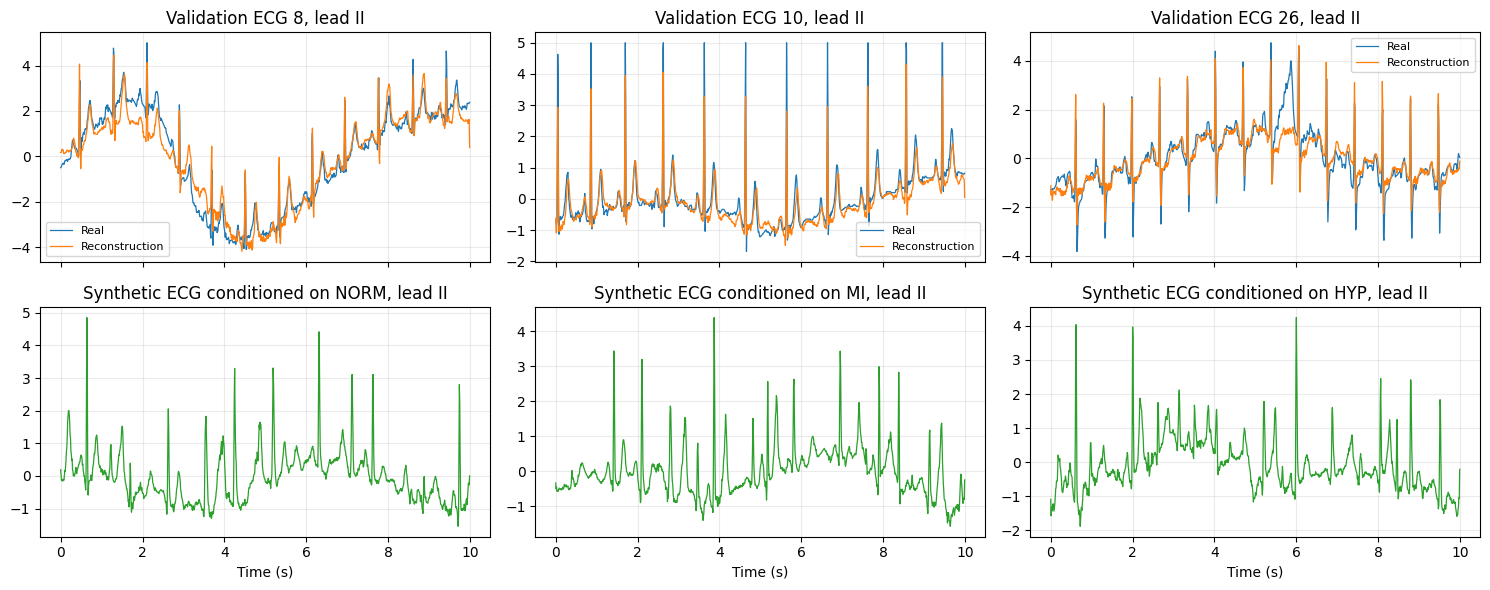

In [60]:
@torch.no_grad()
def reconstruct(model, X, y, bs=256):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        yb = torch.from_numpy(y[i:i + bs].astype(np.float32)).to(device)
        mu, _ = model.encode(xb, yb)                  # use the mean of the latent code
        out.append(model.decode(mu, yb).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def generate(model, y_labels, bs=256, temperature=1.0, seed=0):
    """Sample z ~ N(0, I) and decode it together with the requested label vector."""
    model.eval()
    g = torch.Generator().manual_seed(seed)
    out = []
    for i in range(0, len(y_labels), bs):
        yb = torch.from_numpy(y_labels[i:i + bs].astype(np.float32)).to(device)
        z = (torch.randn(len(yb), LATENT, generator=g) * temperature).to(device)
        out.append(model.decode(z, yb).cpu().numpy())
    return np.concatenate(out)

X_rec = reconstruct(vae, Xv_val, y_val)
mse = float(np.mean((Xv_val - X_rec) ** 2))
a = Xv_val - Xv_val.mean(axis=2, keepdims=True)
b = X_rec - X_rec.mean(axis=2, keepdims=True)
corr = (a * b).sum(axis=2) / (np.sqrt((a ** 2).sum(axis=2) * (b ** 2).sum(axis=2)) + 1e-8)
print(f"Validation reconstruction MSE (normalised units; data variance is about 1): {mse:.3f}")
print(f"Mean real-vs-reconstructed correlation per lead: {corr.mean():.3f} "
      f"(lead II: {corr[:, 1].mean():.3f})")

onehot = np.eye(N_CLASSES, dtype=np.float32)
X_demo = generate(vae, onehot, seed=1)           # one synthetic ECG per class

t = np.arange(1000) / 100.0
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for j in range(3):
    axes[0, j].plot(t, Xv_val[j, 1], lw=0.9, label="Real")
    axes[0, j].plot(t, X_rec[j, 1], lw=0.9, label="Reconstruction")
    axes[0, j].set_title(f"Validation ECG {int(ids_val[j])}, lead II"); axes[0, j].legend(fontsize=8)
for j, cls in enumerate(["NORM", "MI", "HYP"]):
    k = CLASSES.index(cls)
    axes[1, j].plot(t, X_demo[k, 1], lw=0.9, color="tab:green")
    axes[1, j].set_title(f"Synthetic ECG conditioned on {cls}, lead II")
    axes[1, j].set_xlabel("Time (s)")
for ax in axes.ravel():
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "plots", "cvae_real_vs_synthetic.png"), dpi=150, bbox_inches="tight")
plt.show()

In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from scipy.spatial.distance import pdist

X_syn_val = generate(vae, y_val, seed=2)         # same label mix as the validation set

# (1) Can a classifier tell real from synthetic? (AUC 0.5 = indistinguishable, 1.0 = easy to spot)
Fr = extract_in_chunks(Xv_val)
Fs = extract_in_chunks(X_syn_val)
F_pair = np.vstack([Fr, Fs]); lab_pair = np.r_[np.zeros(len(Fr)), np.ones(len(Fs))]
c2st = cross_val_score(RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE),
                       F_pair, lab_pair, cv=5, scoring="roc_auc").mean()
print(f"(1) Real-vs-synthetic detection AUC on summary features: {c2st:.3f}")

# (2) Diversity: average pairwise distance inside each set (500 random ECGs each)
rs = np.random.default_rng(RANDOM_STATE)
sel = rs.choice(len(Xv_val), 500, replace=False)
Dr = downsample(Xv_val[sel]).reshape(500, -1)
Ds = downsample(X_syn_val[sel]).reshape(500, -1)
div_real, div_syn = float(pdist(Dr).mean()), float(pdist(Ds).mean())
print(f"(2) Mean pairwise distance: real={div_real:.2f}, synthetic={div_syn:.2f} "
      f"(ratio {div_syn / div_real:.2f}; much below 1 means low diversity)")

# (3) Memorization: how close is each synthetic ECG to its nearest TRAINING ECG,
#     compared with how close real validation ECGs are to the training set?
def nn_distance(Q, R, chunk=250):
    r2 = (R ** 2).sum(1)
    out = []
    for i in range(0, len(Q), chunk):
        q = Q[i:i + chunk]
        d2 = (q ** 2).sum(1)[:, None] + r2[None, :] - 2.0 * q @ R.T
        out.append(np.sqrt(np.maximum(d2.min(axis=1), 0)))
    return np.concatenate(out)

R_train = downsample(Xv_train).reshape(len(Xv_train), -1).astype(np.float32)
d_syn = nn_distance(Ds.astype(np.float32), R_train)
d_val = nn_distance(Dr.astype(np.float32), R_train)
cut = np.percentile(d_val, 5)
print(f"(3) Nearest-training-ECG distance: synthetic median={np.median(d_syn):.2f}, "
      f"real validation median={np.median(d_val):.2f}")
print(f"    Share of synthetic ECGs closer than the closest 5% of real validation ECGs: "
      f"{(d_syn < cut).mean():.3f} (about 0.05 or less suggests no copying)")

# (4) Label consistency: does the trained CNN-BiLSTM recognise the class each ECG was generated for?
clf_model = ECG_CNN_BiLSTM().to(device)
clf_model.load_state_dict(torch.load(os.path.join(PROJECT_DIR, "models", "CNN-BiLSTM.pt"),
                                     map_location=device))
syn_loader = DataLoader(TensorDataset(torch.from_numpy(X_syn_val), torch.from_numpy(y_val)), batch_size=256)
p_syn = predict_probs(clf_model, syn_loader)
real_loader = DataLoader(TensorDataset(torch.from_numpy(Xv_val), torch.from_numpy(y_val)), batch_size=256)
p_real = predict_probs(clf_model, real_loader)
rows = []
for j, cls in enumerate(CLASSES):
    rows.append({"Class": cls,
                 "AUC on real validation": roc_auc_score(y_val[:, j].astype(int), p_real[:, j]),
                 "AUC on synthetic (vs requested label)": roc_auc_score(y_val[:, j].astype(int), p_syn[:, j])})
label_df = pd.DataFrame(rows).round(3)
print("\n(4) Does the classifier recognise the requested class?")
display(label_df)

quality = {"c2st_auc": round(float(c2st), 3), "diversity_ratio": round(div_syn / div_real, 3),
           "frac_synthetic_closer_than_5pct_real": round(float((d_syn < cut).mean()), 3),
           "recon_mse": round(mse, 3)}
with open(os.path.join(PROJECT_DIR, "processed", "cvae_quality.json"), "w") as f:
    json.dump(quality, f, indent=2)
label_df.to_csv(os.path.join(PROJECT_DIR, "processed", "cvae_label_consistency.csv"), index=False)

/tmp/ipykernel_524/871859196.py:11: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  np.abs(d).mean(2), skew(X, axis=2), kurtosis(X, axis=2)]


(1) Real-vs-synthetic detection AUC on summary features: 1.000
(2) Mean pairwise distance: real=47.29, synthetic=39.07 (ratio 0.83; much below 1 means low diversity)
(3) Nearest-training-ECG distance: synthetic median=28.11, real validation median=28.72
    Share of synthetic ECGs closer than the closest 5% of real validation ECGs: 0.004 (about 0.05 or less suggests no copying)

(4) Does the classifier recognise the requested class?


,Class,AUC on real validation,AUC on synthetic (vs requested label)
0,NORM,0.944,0.641
1,MI,0.930,0.634
2,STTC,0.935,0.714
3,CD,0.934,0.546
4,HYP,0.870,0.568


In [62]:
N_SYN = 6000
SEEDS = [42, 43]          # use [42] first for a quick check; each run takes several minutes

# Oversample rare classes: weight each training label vector by 1 / frequency of its rarest class
freq = y_train.mean(axis=0)
row_w = 1.0 / np.where(y_train == 1, freq[None, :], np.inf).min(axis=1)
row_w = row_w / row_w.sum()
rng_a = np.random.default_rng(RANDOM_STATE)
y_syn = y_train[rng_a.choice(len(y_train), size=N_SYN, p=row_w)].astype(np.float32)
X_syn = generate(vae, y_syn, seed=3)
print("Synthetic set:", X_syn.shape, "| label counts:", y_syn.sum(axis=0).astype(int),
      "| real training label counts:", y_train.sum(axis=0).astype(int))

def train_cnn_bilstm(X_np, y_np, seed):
    torch.manual_seed(seed)
    ds = TensorDataset(torch.from_numpy(X_np), torch.from_numpy(y_np))
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)
    net = ECG_CNN_BiLSTM().to(device)
    with contextlib.redirect_stdout(io.StringIO()):       # hide the per-epoch log
        net, _ = fit(net, loader, val_loader, max_epochs=30, patience=5)
    return net

aug_rows = []
X_aug = np.concatenate([X_train_norm, X_syn]).astype(np.float32)
y_aug = np.concatenate([y_train, y_syn]).astype(np.float32)

for seed in SEEDS:
    for label, (Xa, ya) in {"Real only": (X_train_norm, y_train),
                            "Real + synthetic": (X_aug, y_aug)}.items():
        print(f"Training CNN-BiLSTM | seed {seed} | {label} ({len(Xa)} ECGs)...")
        net = train_cnn_bilstm(Xa, ya, seed)
        p_v, p_t = predict_probs(net, val_loader), predict_probs(net, test_loader)
        thr = tune_thresholds(y_val, p_v)                 # thresholds chosen on validation only
        table, f1_tuned, auc_test = evaluate(y_test, p_t, thr)
        aug_rows.append({"Seed": seed, "Training data": label,
                         "Macro-F1 (tuned)": round(f1_tuned, 3),
                         "Macro-AUC": round(auc_test, 3),
                         "HYP F1": round(float(table.loc[table["Class"] == "HYP", "F1"].iloc[0]), 3)})
        print("   ", aug_rows[-1])

aug_df = pd.DataFrame(aug_rows)
display(aug_df)
display(aug_df.groupby("Training data")[["Macro-F1 (tuned)", "Macro-AUC", "HYP F1"]].mean().round(3))
aug_df.to_csv(os.path.join(PROJECT_DIR, "processed", "augmentation_results.csv"), index=False)

Synthetic set: (6000, 12, 1000) | label counts: [1649 1874 1993 1792 1572] | real training label counts: [7596 4379 4186 3907 2119]
Training CNN-BiLSTM | seed 42 | Real only (17084 ECGs)...
    {'Seed': 42, 'Training data': 'Real only', 'Macro-F1 (tuned)': np.float64(0.75), 'Macro-AUC': np.float64(0.927), 'HYP F1': 0.605}
Training CNN-BiLSTM | seed 42 | Real + synthetic (23084 ECGs)...
    {'Seed': 42, 'Training data': 'Real + synthetic', 'Macro-F1 (tuned)': np.float64(0.735), 'Macro-AUC': np.float64(0.919), 'HYP F1': 0.599}
Training CNN-BiLSTM | seed 43 | Real only (17084 ECGs)...
    {'Seed': 43, 'Training data': 'Real only', 'Macro-F1 (tuned)': np.float64(0.738), 'Macro-AUC': np.float64(0.923), 'HYP F1': 0.605}
Training CNN-BiLSTM | seed 43 | Real + synthetic (23084 ECGs)...
    {'Seed': 43, 'Training data': 'Real + synthetic', 'Macro-F1 (tuned)': np.float64(0.733), 'Macro-AUC': np.float64(0.917), 'HYP F1': 0.586}


,Seed,Training data,Macro-F1 (tuned),Macro-AUC,HYP F1
0,42,Real only,0.750,0.927,0.605
1,42,Real + synthetic,0.735,0.919,0.599
2,43,Real only,0.738,0.923,0.605
3,43,Real + synthetic,0.733,0.917,0.586


,Macro-F1 (tuned),Macro-AUC,HYP F1
Training data,,,
Real + synthetic,0.734,0.918,0.592
Real only,0.744,0.925,0.605


In [63]:
rf_diag = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE).fit(F_pair, lab_pair)
imp = pd.Series(rf_diag.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp.head(8).round(3))
print(imp.groupby(lambda n: n.rsplit("_", 1)[0]).sum().sort_values(ascending=False).round(3))

mean|diff|_aVR    0.103
mean_V3           0.101
mean_V4           0.097
mean_V2           0.072
std_V5            0.054
mean|diff|_II     0.053
std_V4            0.040
mean|diff|_I      0.040
dtype: float64
mean          0.318
mean|diff|    0.298
std           0.143
max           0.067
min           0.055
p5            0.054
p95           0.030
kurtosis      0.018
skew          0.018
dtype: float64


### Gaussian-Bernoulli RBM


In [64]:
from scipy.special import expit as sigmoid

class RBM:
    """RBM trained with CD-k. visible='gaussian' (continuous, unit variance) or 'binary' (values in [0, 1])."""
    def __init__(self, n_visible, n_hidden, visible="gaussian", seed=RANDOM_STATE):
        self.rng = np.random.default_rng(seed)
        self.visible = visible
        self.W = self.rng.normal(0, 0.01, (n_visible, n_hidden)).astype(np.float32)
        self.b = np.zeros(n_visible, dtype=np.float32)    # visible bias
        self.c = np.zeros(n_hidden, dtype=np.float32)     # hidden bias

    def hidden_prob(self, v):
        return sigmoid(v @ self.W + self.c)

    def visible_mean(self, h):
        x = h @ self.W.T + self.b
        return x if self.visible == "gaussian" else sigmoid(x)

    def reconstruct(self, v):
        return self.visible_mean(self.hidden_prob(v))

    def free_energy(self, v):
        hidden_term = np.logaddexp(0, v @ self.W + self.c).sum(axis=1)
        if self.visible == "gaussian":
            return 0.5 * ((v - self.b) ** 2).sum(axis=1) - hidden_term
        return -(v @ self.b) - hidden_term

    def fit(self, V_train, V_val, epochs=30, lr=1e-3, batch=100, weight_decay=1e-4, cd_k=1, label="RBM"):
        n = len(V_train)
        vel_W, vel_b, vel_c = np.zeros_like(self.W), np.zeros_like(self.b), np.zeros_like(self.c)
        hist = {"train_mse": [], "val_mse": [], "fe_gap": []}
        best_mse, best_params = np.inf, None
        for epoch in range(epochs):
            momentum = 0.5 if epoch < 5 else 0.9
            order = self.rng.permutation(n)
            for i in range(0, n, batch):
                v0 = V_train[order[i:i + batch]]
                h0p = self.hidden_prob(v0)
                h = (self.rng.random(h0p.shape) < h0p).astype(np.float32)
                for _ in range(cd_k):
                    v1 = self.visible_mean(h)
                    h1p = self.hidden_prob(v1)
                    h = (self.rng.random(h1p.shape) < h1p).astype(np.float32)
                B = len(v0)
                grad_W = (v0.T @ h0p - v1.T @ h1p) / B - weight_decay * self.W
                vel_W = momentum * vel_W + lr * grad_W
                vel_b = momentum * vel_b + lr * (v0 - v1).mean(axis=0)
                vel_c = momentum * vel_c + lr * (h0p - h1p).mean(axis=0)
                self.W += vel_W; self.b += vel_b; self.c += vel_c
            tr = float(np.mean((V_train - self.reconstruct(V_train)) ** 2))
            va = float(np.mean((V_val - self.reconstruct(V_val)) ** 2))
            gap = float(self.free_energy(V_val).mean() - self.free_energy(V_train[:len(V_val)]).mean())
            hist["train_mse"].append(tr); hist["val_mse"].append(va); hist["fe_gap"].append(gap)
            if va < best_mse:
                best_mse, best_params = va, (self.W.copy(), self.b.copy(), self.c.copy())
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"{label} epoch {epoch+1:02d} | train MSE={tr:.4f} | val MSE={va:.4f} | free-energy gap (val-train)={gap:.2f}")
        self.W, self.b, self.c = best_params
        print(f"{label}: best validation reconstruction MSE = {best_mse:.4f}")
        return hist

# Inputs: the 108 standardised summary features from Step 2, with extreme values clipped
RBM_CLIP = 5.0
Fc_train, Fc_val, Fc_test = (np.clip(F, -RBM_CLIP, RBM_CLIP).astype(np.float32)
                             for F in (F_train_s, F_val_s, F_test_s))
print("Data variance per feature (reference for reconstruction MSE):", round(float(Fc_val.var(axis=0).mean()), 3))

# ---- RBM: Gaussian visible units (108 features) -> 64 binary hidden units ----
rbm1 = RBM(Fc_train.shape[1], 64, visible="gaussian")
hist1 = rbm1.fit(Fc_train, Fc_val, epochs=40, lr=1e-3, label="Gaussian-Bernoulli RBM")

H1_train, H1_val, H1_test = (rbm1.hidden_prob(F) for F in (Fc_train, Fc_val, Fc_test))
eval_representation("RBM (64 hidden units)", H1_train, H1_val, H1_test)

# What does each hidden unit respond to? (largest weights)
print("\nStrongest input features for the first 4 hidden units:")
for h_idx in range(4):
    w = rbm1.W[:, h_idx]
    top = np.argsort(-np.abs(w))[:5]
    print(f"  Hidden {h_idx}:", ", ".join(f"{feature_names[i]} ({w[i]:+.2f})" for i in top))

# Does the RBM capture the dependencies between features? Compare Gibbs samples with real data.
v = Fc_train[:2000].copy()
for _ in range(200):
    h = (rbm1.rng.random((len(v), 64)) < rbm1.hidden_prob(v)).astype(np.float32)
    v = rbm1.visible_mean(h) + rbm1.rng.standard_normal(v.shape).astype(np.float32)
v_model = rbm1.visible_mean(rbm1.hidden_prob(v))       # noise-free version of the final sample
ref = Fc_train[:2000]
iu = np.triu_indices(ref.shape[1], k=1)
c_real = np.nan_to_num(np.corrcoef(ref.T))[iu]
c_model = np.nan_to_num(np.corrcoef(v_model.T))[iu]
print(f"\nGibbs samples vs real data: mean |difference| of feature means = "
      f"{np.abs(v_model.mean(0) - ref.mean(0)).mean():.3f}; "
      f"correlation between the two feature-correlation matrices = {np.corrcoef(c_real, c_model)[0, 1]:.3f}")

Data variance per feature (reference for reconstruction MSE): 0.747
Gaussian-Bernoulli RBM epoch 01 | train MSE=0.7583 | val MSE=0.7322 | free-energy gap (val-train)=-1.01
Gaussian-Bernoulli RBM epoch 05 | train MSE=0.4679 | val MSE=0.4566 | free-energy gap (val-train)=-1.28
Gaussian-Bernoulli RBM epoch 10 | train MSE=0.2522 | val MSE=0.2440 | free-energy gap (val-train)=-1.01
Gaussian-Bernoulli RBM epoch 15 | train MSE=0.2010 | val MSE=0.1931 | free-energy gap (val-train)=-0.80
Gaussian-Bernoulli RBM epoch 20 | train MSE=0.1790 | val MSE=0.1713 | free-energy gap (val-train)=-0.67
Gaussian-Bernoulli RBM epoch 25 | train MSE=0.1669 | val MSE=0.1596 | free-energy gap (val-train)=-0.65
Gaussian-Bernoulli RBM epoch 30 | train MSE=0.1593 | val MSE=0.1524 | free-energy gap (val-train)=-0.60
Gaussian-Bernoulli RBM epoch 35 | train MSE=0.1538 | val MSE=0.1472 | free-energy gap (val-train)=-0.55
Gaussian-Bernoulli RBM epoch 40 | train MSE=0.1498 | val MSE=0.1434 | free-energy gap (val-train)=-0

### stack them into a Deep Belief Network

In [65]:
rbm2 = RBM(64, 32, visible="binary", seed=RANDOM_STATE + 1)
hist2 = rbm2.fit(H1_train, H1_val, epochs=40, lr=0.05, label="RBM layer 2 (64->32)")
H2_train, H2_val, H2_test = (rbm2.hidden_prob(H) for H in (H1_train, H1_val, H1_test))

rbm3 = RBM(32, 16, visible="binary", seed=RANDOM_STATE + 2)
hist3 = rbm3.fit(H2_train, H2_val, epochs=40, lr=0.05, label="RBM layer 3 (32->16)")
H3_train, H3_val, H3_test = (rbm3.hidden_prob(H) for H in (H2_train, H2_val, H2_test))

eval_representation("DBN layer 2 (32 hidden units)", H2_train, H2_val, H2_test)
eval_representation("DBN layer 3 (16 hidden units)", H3_train, H3_val, H3_test)

# How much of the original 108 features can each layer reconstruct (top-down pass, no sampling)?
def dbn_reconstruct(F, depth):
    h = rbm1.hidden_prob(F)
    if depth >= 2: h = rbm2.hidden_prob(h)
    if depth >= 3: h = rbm3.hidden_prob(h)
    if depth >= 3: h = rbm3.visible_mean(h)
    if depth >= 2: h = rbm2.visible_mean(h)
    return rbm1.visible_mean(h)

var_ref = float(Fc_val.var(axis=0).mean())
dbn_rows = []
for depth, units in ((1, 64), (2, 32), (3, 16)):
    mse = float(np.mean((Fc_val - dbn_reconstruct(Fc_val, depth)) ** 2))
    dbn_rows.append({"Depth": depth, "Top layer units": units,
                     "Feature reconstruction MSE (val)": round(mse, 3),
                     "Share of variance unexplained": round(mse / var_ref, 3)})
print("\nDeep Belief Network: reconstruction of the 108 features by depth")
display(pd.DataFrame(dbn_rows))

RBM layer 2 (64->32) epoch 01 | train MSE=0.0762 | val MSE=0.0759 | free-energy gap (val-train)=-0.69
RBM layer 2 (64->32) epoch 05 | train MSE=0.0326 | val MSE=0.0332 | free-energy gap (val-train)=-0.70
RBM layer 2 (64->32) epoch 10 | train MSE=0.0154 | val MSE=0.0156 | free-energy gap (val-train)=-0.53
RBM layer 2 (64->32) epoch 15 | train MSE=0.0146 | val MSE=0.0149 | free-energy gap (val-train)=-0.48
RBM layer 2 (64->32) epoch 20 | train MSE=0.0139 | val MSE=0.0141 | free-energy gap (val-train)=-0.47
RBM layer 2 (64->32) epoch 25 | train MSE=0.0136 | val MSE=0.0138 | free-energy gap (val-train)=-0.47
RBM layer 2 (64->32) epoch 30 | train MSE=0.0136 | val MSE=0.0139 | free-energy gap (val-train)=-0.52
RBM layer 2 (64->32) epoch 35 | train MSE=0.0132 | val MSE=0.0135 | free-energy gap (val-train)=-0.45
RBM layer 2 (64->32) epoch 40 | train MSE=0.0132 | val MSE=0.0134 | free-energy gap (val-train)=-0.48
RBM layer 2 (64->32): best validation reconstruction MSE = 0.0131
RBM layer 3 (32-

,Depth,Top layer units,Feature reconstruction MSE (val),Share of variance unexplained
0,1,64,0.143,0.192
1,2,32,0.231,0.309
2,3,16,0.306,0.409


###does DBN pre-training help? (PyTorch)

In [66]:
import io, contextlib

def make_loader(Fx, yx, shuffle):
    return DataLoader(TensorDataset(torch.from_numpy(Fx), torch.from_numpy(yx.astype(np.float32))),
                      batch_size=128, shuffle=shuffle)
dbn_train_loader = make_loader(Fc_train, y_train, True)
dbn_val_loader = make_loader(Fc_val, y_val, False)
dbn_test_loader = make_loader(Fc_test, y_test, False)

def build_mlp():
    return nn.Sequential(nn.Linear(108, 64), nn.Sigmoid(),
                         nn.Linear(64, 32), nn.Sigmoid(),
                         nn.Linear(32, 16), nn.Sigmoid(),
                         nn.Linear(16, len(CLASSES)))

def load_dbn_weights(net):
    linear_layers = [m for m in net if isinstance(m, nn.Linear)]
    for layer, rbm in zip(linear_layers[:3], (rbm1, rbm2, rbm3)):
        layer.weight.data.copy_(torch.from_numpy(rbm.W.T.copy()).float())   # RBM weights W: (visible, hidden)
        layer.bias.data.copy_(torch.from_numpy(rbm.c.copy()).float())

ft_rows = []
for seed in (42, 43, 44):
    for mode in ("Random init", "DBN pre-trained"):
        torch.manual_seed(seed)
        net = build_mlp().to(device)
        if mode == "DBN pre-trained":
            load_dbn_weights(net)
        with contextlib.redirect_stdout(io.StringIO()):          # hide the per-epoch log
            net, _ = fit(net, dbn_train_loader, dbn_val_loader, max_epochs=50, patience=7)
        p_v, p_t = predict_probs(net, dbn_val_loader), predict_probs(net, dbn_test_loader)
        thr = tune_thresholds(y_val, p_v)                         # thresholds chosen on validation only
        _, f1_t, auc_t = evaluate(y_test, p_t, thr)
        ft_rows.append({"Seed": seed, "Initialisation": mode,
                        "Macro-F1 (tuned)": round(f1_t, 3), "Macro-AUC": round(auc_t, 3)})

ft_df = pd.DataFrame(ft_rows)
display(ft_df)
display(ft_df.groupby("Initialisation")[["Macro-F1 (tuned)", "Macro-AUC"]].agg(["mean", "std"]).round(3))
ft_df.to_csv(os.path.join(PROJECT_DIR, "processed", "dbn_pretraining_results.csv"), index=False)

,Seed,Initialisation,Macro-F1 (tuned),Macro-AUC
0,42,Random init,0.625,0.844
1,42,DBN pre-trained,0.643,0.857
2,43,Random init,0.626,0.843
3,43,DBN pre-trained,0.635,0.855
4,44,Random init,0.617,0.844
5,44,DBN pre-trained,0.639,0.856


Macro-F1 (tuned)        Macro-AUC       
                            mean    std      mean    std
Initialisation                                          
DBN pre-trained            0.639  0.004     0.856  0.001
Random init                0.623  0.005     0.844  0.001

###Responsible-AI analysis

In [67]:
import json
from sklearn.metrics import roc_auc_score, f1_score

ra_dir = os.path.join(PROJECT_DIR, "processed", "responsible_ai")
os.makedirs(ra_dir, exist_ok=True)

final_net = ECG_CNN_BiLSTM().to(device)
final_net.load_state_dict(torch.load(os.path.join(PROJECT_DIR, "models", "CNN-BiLSTM.pt"), map_location=device))
final_net.eval()

def predict_on_array(X, bs=256):
    """Probabilities from the final CNN-BiLSTM for any (N, 12, 1000) array."""
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32)),
                       torch.zeros(len(X), len(CLASSES)))
    return predict_probs(final_net, DataLoader(ds, batch_size=bs))

# Thresholds are chosen on the VALIDATION set only, from this exact model
THR = tune_thresholds(y_val, predict_on_array(X_val_norm))
P = predict_on_array(X_test_norm)
Y = y_test.astype(int)
PRED = (P >= THR).astype(int)

print("Thresholds:", dict(zip(CLASSES, np.round(THR, 2))))
print(f"Test macro-AUC = {np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in range(5)]):.3f}, "
      f"macro-F1 = {f1_score(Y, PRED, average='macro', zero_division=0):.3f}")

# Attach age and sex to each test recording, in the same order as the arrays
meta = test_df.set_index("ecg_id").loc[ids_test].reset_index()
assert (meta["ecg_id"].to_numpy() == ids_test).all()
assert (meta[TARGET_COLS].to_numpy() == Y).all(), "labels in metadata do not match the test arrays"
print("Metadata alignment check: PASSED")
print(meta["sex_label"].value_counts(dropna=False).to_dict())
print(meta["age_group"].value_counts(dropna=False).to_dict())

Thresholds: {'NORM': np.float64(0.47), 'MI': np.float64(0.42), 'STTC': np.float64(0.22), 'CD': np.float64(0.34), 'HYP': np.float64(0.43)}
Test macro-AUC = 0.927, macro-F1 = 0.748
Metadata alignment check: PASSED
{'Male': 1110, 'Female': 1048}
{'60-79': 914, '40-59': 639, '80-89': 289, '18-39': 271, '90+': 32, 'Under 18': 13}


###performance by sex and age

,Group,n,Macro-AUC,AUC 95% CI,Macro-F1,Sens NORM,Sens MI,Sens STTC,Sens CD,Sens HYP,Interpretable
0,All test recordings,2158,0.927,0.920-0.934,0.748,0.918,0.749,0.845,0.720,0.531,yes
1,Sex: Female,1048,0.916,0.905-0.926,0.736,0.919,0.700,0.856,0.683,0.559,yes
2,Sex: Male,1110,0.937,0.928-0.946,0.758,0.917,0.791,0.830,0.752,0.504,yes
3,Age: Under 18,13,0.762,0.486-0.945,0.393,0.667,NaN,NaN,0.571,NaN,no (small n)
4,Age: 18-39,271,0.939,0.916-0.961,0.697,0.965,0.667,0.632,0.633,0.556,yes
5,Age: 40-59,639,0.925,0.908-0.940,0.713,0.938,0.726,0.857,0.635,0.326,yes
6,Age: 60-79,914,0.918,0.904-0.928,0.736,0.890,0.728,0.842,0.686,0.557,yes
7,Age: 80-89,289,0.878,0.856-0.901,0.681,0.524,0.809,0.863,0.866,0.600,yes
8,Age: 90+,32,0.921,0.849-0.978,0.661,NaN,0.867,0.947,0.875,0.600,no (small n)



Largest macro-AUC gap between interpretable groups: 0.061 (Age: 18-39 vs Age: 80-89)


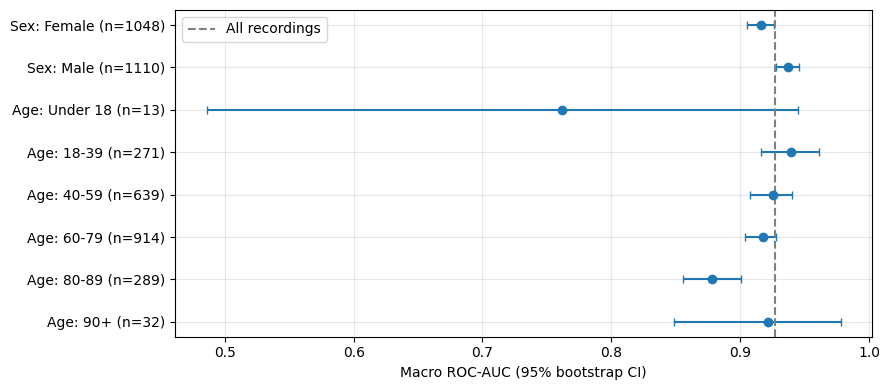

In [68]:
MIN_N = 50   # groups smaller than this are shown but should not be interpreted

def metrics_for(mask, n_boot=300, seed=0):
    idx = np.where(mask)[0]
    y, p, pr = Y[idx], P[idx], PRED[idx]
    valid = [j for j in range(len(CLASSES)) if y[:, j].sum() >= 5 and (1 - y[:, j]).sum() >= 5]
    aucs = [roc_auc_score(y[:, j], p[:, j]) for j in valid]
    macro_auc = float(np.mean(aucs)) if aucs else np.nan
    lo = hi = np.nan
    if valid:
        rng = np.random.default_rng(seed)
        boots = []
        for _ in range(n_boot):
            b = rng.integers(0, len(idx), len(idx))
            yb, pb = y[b], p[b]
            vals = [roc_auc_score(yb[:, j], pb[:, j]) for j in valid if 0 < yb[:, j].sum() < len(b)]
            if len(vals) == len(valid):
                boots.append(np.mean(vals))
        if len(boots) >= 50:
            lo, hi = np.percentile(boots, [2.5, 97.5])
    row = {"n": len(idx), "Macro-AUC": macro_auc, "AUC 95% CI": f"{lo:.3f}-{hi:.3f}" if not np.isnan(lo) else "n/a",
           "Macro-F1": f1_score(y, pr, average="macro", zero_division=0)}
    for j, cls in enumerate(CLASSES):                      # sensitivity (recall) per class
        row[f"Sens {cls}"] = float(pr[y[:, j] == 1, j].mean()) if y[:, j].sum() >= 5 else np.nan
    return row

age_order = ["Under 18", "18-39", "40-59", "60-79", "80-89", "90+"]
rows = [dict(Group="All test recordings", **metrics_for(np.ones(len(Y), dtype=bool)))]
for g in ["Female", "Male"]:
    rows.append(dict(Group=f"Sex: {g}", **metrics_for((meta["sex_label"] == g).to_numpy())))
for g in age_order:
    rows.append(dict(Group=f"Age: {g}", **metrics_for((meta["age_group"] == g).to_numpy())))
sub_df = pd.DataFrame(rows)
sub_df["Interpretable"] = np.where(sub_df["n"] >= MIN_N, "yes", "no (small n)")
display(sub_df.round(3))
sub_df.to_csv(os.path.join(ra_dir, "subgroup_performance.csv"), index=False)

ok = sub_df[(sub_df["Group"] != "All test recordings") & (sub_df["n"] >= MIN_N)]
print(f"\nLargest macro-AUC gap between interpretable groups: "
      f"{ok['Macro-AUC'].max() - ok['Macro-AUC'].min():.3f} "
      f"({ok.loc[ok['Macro-AUC'].idxmax(), 'Group']} vs {ok.loc[ok['Macro-AUC'].idxmin(), 'Group']})")

# Plot macro-AUC with confidence intervals
plot_df = sub_df[sub_df["Group"] != "All test recordings"].copy()
ci = plot_df["AUC 95% CI"].str.split("-", expand=True).replace("n/a", np.nan).astype(float)
plot_df["lo"], plot_df["hi"] = ci[0].values, ci[1].values
fig, ax = plt.subplots(figsize=(9, 4))
ypos = np.arange(len(plot_df))
ax.errorbar(plot_df["Macro-AUC"], ypos,
            xerr=[plot_df["Macro-AUC"] - plot_df["lo"], plot_df["hi"] - plot_df["Macro-AUC"]],
            fmt="o", capsize=3)
ax.set_yticks(ypos); ax.set_yticklabels([f"{g} (n={n})" for g, n in zip(plot_df["Group"], plot_df["n"])])
ax.axvline(sub_df.loc[0, "Macro-AUC"], color="gray", ls="--", label="All recordings")
ax.invert_yaxis(); ax.set_xlabel("Macro ROC-AUC (95% bootstrap CI)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(ra_dir, "subgroup_auc.png"), dpi=150, bbox_inches="tight")
plt.show()

###robustness tests

,Condition,Macro-AUC,Macro-F1 (fixed thresholds),AUC change vs clean,F1 change vs clean
0,Clean,0.927,0.748,0.000,0.000
1,Gaussian noise (sigma=0.1),0.927,0.744,-0.000,-0.004
2,Gaussian noise (sigma=0.25),0.925,0.737,-0.002,-0.011
3,Gaussian noise (sigma=0.5),0.915,0.689,-0.012,-0.059
4,Gaussian noise (sigma=1.0),0.886,0.511,-0.041,-0.237
5,Amplitude x0.5,0.879,0.575,-0.048,-0.173
6,Amplitude x0.75,0.918,0.681,-0.009,-0.067
7,Amplitude x1.25,0.920,0.721,-0.007,-0.027
8,Amplitude x1.5,0.909,0.665,-0.018,-0.083
9,"Baseline wander (0.3 Hz, amp=0.5)",0.924,0.744,-0.003,-0.004


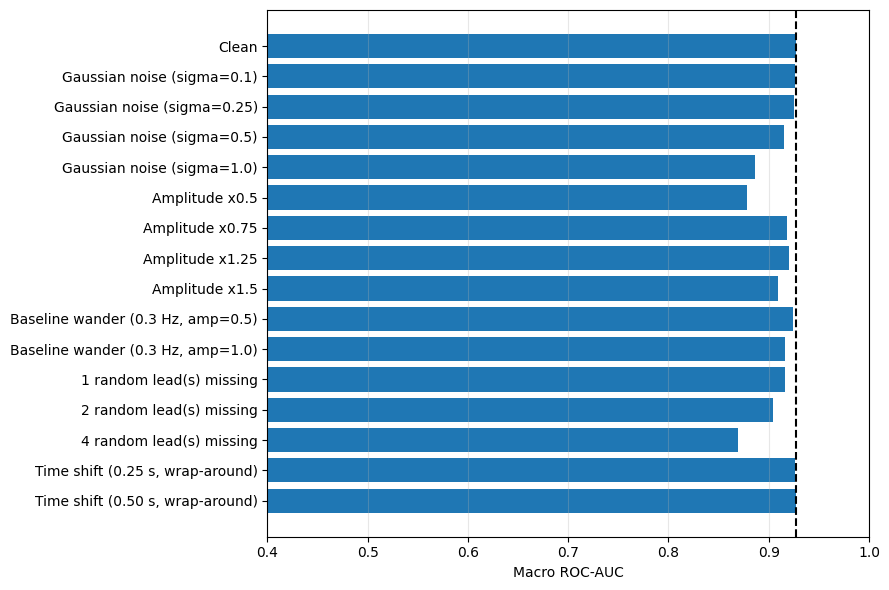

In [69]:
rng_r = np.random.default_rng(RANDOM_STATE)

def add_wander(X, amp, f=0.3):
    t = np.arange(X.shape[2]) / 100.0
    phase = rng_r.uniform(0, 2 * np.pi, (len(X), 1, 1))
    return (X + amp * np.sin(2 * np.pi * f * t[None, None, :] + phase)).astype(np.float32)

def drop_leads(X, k):
    Xd = X.copy()
    for i in range(len(Xd)):
        Xd[i, rng_r.choice(12, k, replace=False)] = 0.0        # 0 = the normalised mean level
    return Xd

conditions = [("Clean", lambda: X_test_norm)]
for s in (0.1, 0.25, 0.5, 1.0):
    conditions.append((f"Gaussian noise (sigma={s})",
                       lambda s=s: (X_test_norm + rng_r.normal(0, s, X_test_norm.shape)).astype(np.float32)))
for a in (0.5, 0.75, 1.25, 1.5):
    conditions.append((f"Amplitude x{a}", lambda a=a: (X_test_norm * a).astype(np.float32)))
for amp in (0.5, 1.0):
    conditions.append((f"Baseline wander (0.3 Hz, amp={amp})", lambda amp=amp: add_wander(X_test_norm, amp)))
for k in (1, 2, 4):
    conditions.append((f"{k} random lead(s) missing", lambda k=k: drop_leads(X_test_norm, k)))
for sh in (25, 50):
    conditions.append((f"Time shift ({sh/100:.2f} s, wrap-around)", lambda sh=sh: np.roll(X_test_norm, sh, axis=2)))

rob_rows = []
for name, make in conditions:
    Pp = predict_on_array(make())
    rob_rows.append({"Condition": name,
                     "Macro-AUC": np.mean([roc_auc_score(Y[:, j], Pp[:, j]) for j in range(5)]),
                     "Macro-F1 (fixed thresholds)": f1_score(Y, (Pp >= THR).astype(int), average="macro", zero_division=0)})
rob_df = pd.DataFrame(rob_rows)
rob_df["AUC change vs clean"] = rob_df["Macro-AUC"] - rob_df.loc[0, "Macro-AUC"]
rob_df["F1 change vs clean"] = rob_df["Macro-F1 (fixed thresholds)"] - rob_df.loc[0, "Macro-F1 (fixed thresholds)"]
display(rob_df.round(3))
rob_df.to_csv(os.path.join(ra_dir, "robustness.csv"), index=False)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rob_df["Condition"], rob_df["Macro-AUC"], color="tab:blue")
ax.axvline(rob_df.loc[0, "Macro-AUC"], color="k", ls="--")
ax.set_xlim(0.4, 1.0); ax.invert_yaxis(); ax.set_xlabel("Macro ROC-AUC"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(ra_dir, "robustness.png"), dpi=150, bbox_inches="tight")
plt.show()

###failures and calibration

(1) Errors per class


,Class,Missed (FN),False alarms (FP),Sensitivity,Specificity
0,NORM,79,208,0.918,0.826
1,MI,138,136,0.749,0.915
2,STTC,81,163,0.845,0.900
3,CD,139,84,0.720,0.949
4,HYP,123,74,0.531,0.961


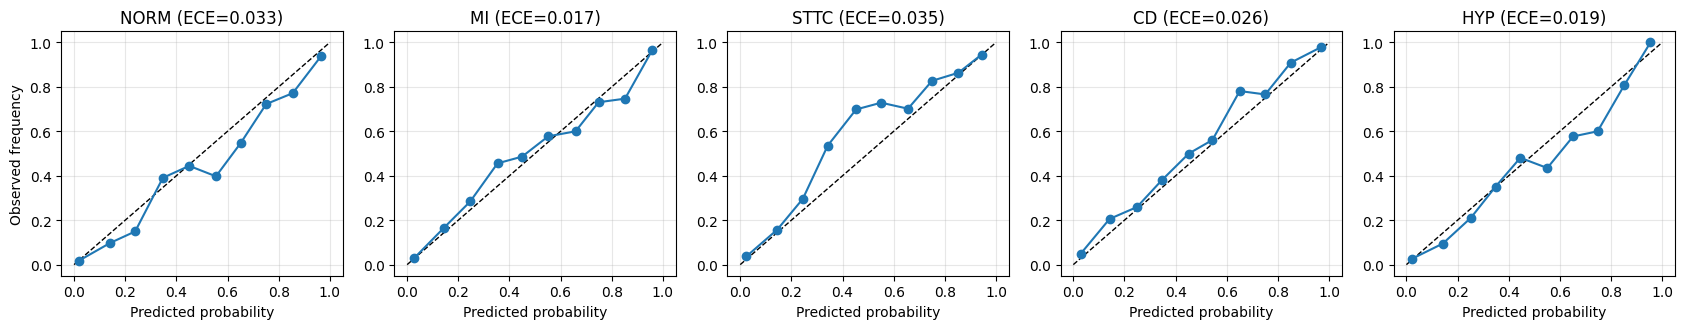


(3) Exact-match rate by number of true diagnoses


,n,Exact-match rate
True diagnoses,,
1,1650,0.702
2,398,0.379
3+,110,0.345



(4) Artifact-heavy test recordings (small group, interpret with caution)


,Recordings,n,Macro-F1,Exact-match rate
0,Flagged (artifact-heavy),21,0.745,0.619
1,Not flagged,2137,0.746,0.624



(5) Ten most confidently wrong test recordings


,ecg_id,age,sex,true labels,predicted labels,worst class,predicted prob. of worst class,flagged artifact
0,1745,71.0,Female,HYP,NORM,HYP,0.003,False
1,4167,66.0,Female,NORM+CD+HYP,NORM,HYP,0.004,False
2,19461,42.0,Female,NORM+CD,NORM,CD,0.005,False
3,19664,85.0,Female,CD+HYP,NORM,HYP,0.005,False
4,2909,48.0,Female,NORM+CD,NORM,CD,0.006,False
5,17648,58.0,Female,STTC,NORM,STTC,0.007,False
6,11132,64.0,Male,STTC+HYP,NORM,STTC,0.007,False
7,1447,64.0,Female,MI+HYP,NORM,MI,0.008,False
8,13292,65.0,Female,STTC+HYP,MI+STTC,HYP,0.009,False
9,3248,34.0,Male,NORM+CD,NORM,CD,0.009,False


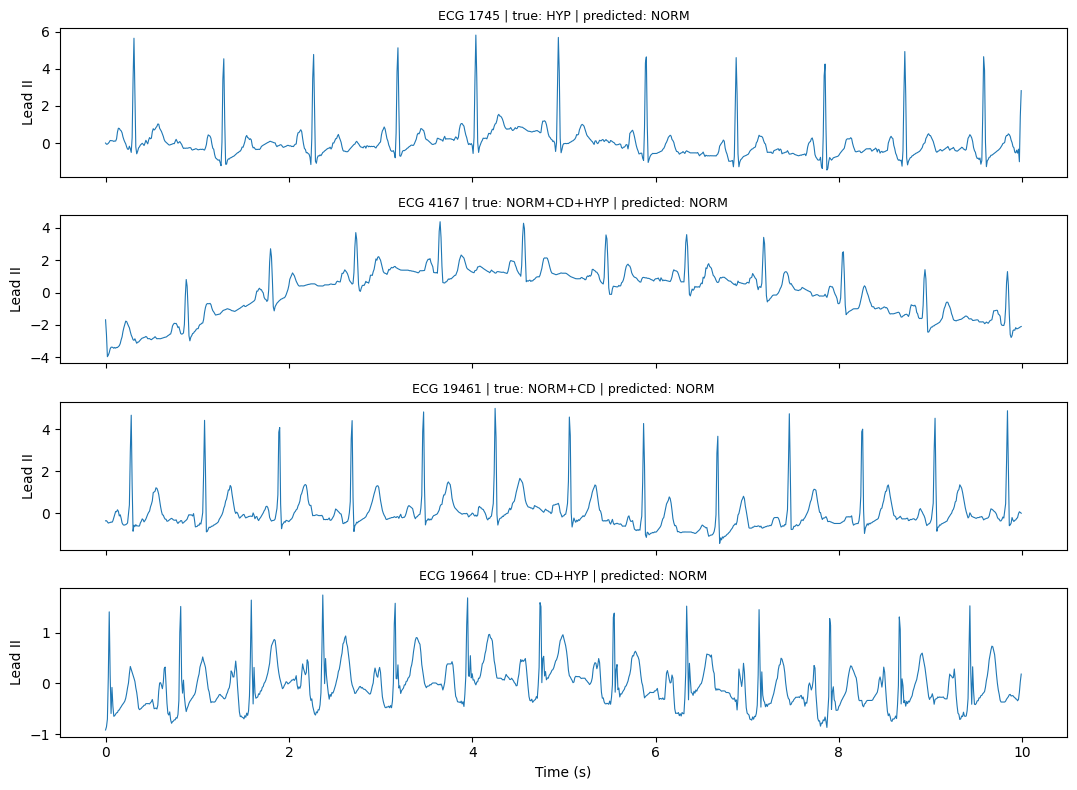

In [70]:
# (1) Errors per class at the validation-tuned thresholds
err_rows = []
for j, cls in enumerate(CLASSES):
    tp = int(((PRED[:, j] == 1) & (Y[:, j] == 1)).sum()); fn = int(((PRED[:, j] == 0) & (Y[:, j] == 1)).sum())
    fp = int(((PRED[:, j] == 1) & (Y[:, j] == 0)).sum()); tn = int(((PRED[:, j] == 0) & (Y[:, j] == 0)).sum())
    err_rows.append({"Class": cls, "Missed (FN)": fn, "False alarms (FP)": fp,
                     "Sensitivity": tp / max(tp + fn, 1), "Specificity": tn / max(tn + fp, 1)})
print("(1) Errors per class")
display(pd.DataFrame(err_rows).round(3))

# (2) Calibration: do predicted probabilities match how often the class really occurs?
def ece(y, p, bins=10):
    b = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1])
    return float(sum(abs(y[b == k].mean() - p[b == k].mean()) * (b == k).sum() / len(y)
                     for k in range(bins) if (b == k).any()))

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
ece_rows = []
for j, cls in enumerate(CLASSES):
    frac_pos, mean_pred = [], []
    b = np.digitize(P[:, j], np.linspace(0, 1, 11)[1:-1])
    for k in range(10):
        if (b == k).sum() >= 10:
            frac_pos.append(Y[b == k, j].mean()); mean_pred.append(P[b == k, j].mean())
    axes[j].plot([0, 1], [0, 1], "k--", lw=1)
    axes[j].plot(mean_pred, frac_pos, marker="o")
    axes[j].set_title(f"{cls} (ECE={ece(Y[:, j], P[:, j]):.3f})")
    axes[j].set_xlabel("Predicted probability"); axes[j].grid(alpha=0.3)
    ece_rows.append({"Class": cls, "ECE": round(ece(Y[:, j], P[:, j]), 3)})
axes[0].set_ylabel("Observed frequency")
plt.tight_layout()
plt.savefig(os.path.join(ra_dir, "calibration.png"), dpi=150, bbox_inches="tight")
plt.show()

# (3) Exact-match rate (all five labels right) by number of true diagnoses
exact = (PRED == Y).all(axis=1)
n_true = Y.sum(axis=1)
by_count = pd.DataFrame({"True diagnoses": np.where(n_true >= 3, "3+", n_true.astype(str)), "exact": exact}
                        ).groupby("True diagnoses")["exact"].agg(["count", "mean"]).rename(
                        columns={"count": "n", "mean": "Exact-match rate"})
print("\n(3) Exact-match rate by number of true diagnoses")
display(by_count.round(3))

# (4) Artifact-heavy recordings (flagged earlier) versus the rest
if "flags" in globals():
    fl = flags["test"]
    comp = pd.DataFrame({
        "Recordings": ["Flagged (artifact-heavy)", "Not flagged"],
        "n": [int(fl.sum()), int((~fl).sum())],
        "Macro-F1": [f1_score(Y[fl], PRED[fl], average="macro", zero_division=0),
                     f1_score(Y[~fl], PRED[~fl], average="macro", zero_division=0)],
        "Exact-match rate": [exact[fl].mean(), exact[~fl].mean()]})
    print("\n(4) Artifact-heavy test recordings (small group, interpret with caution)")
    display(comp.round(3))

# (5) The most confidently wrong recordings
def labels_str(row):
    return "+".join(c for c, v in zip(CLASSES, row) if v) or "none"

worst_gap = np.abs(P - Y)                          # distance of each probability from the truth
worst_score = worst_gap.max(axis=1)
worst_class = worst_gap.argmax(axis=1)
order = np.argsort(-worst_score)[:10]
fail_df = pd.DataFrame({
    "ecg_id": ids_test[order], "age": meta["age_clean"].to_numpy()[order],
    "sex": meta["sex_label"].to_numpy()[order],
    "true labels": [labels_str(Y[i]) for i in order],
    "predicted labels": [labels_str(PRED[i]) for i in order],
    "worst class": [CLASSES[worst_class[i]] for i in order],
    "predicted prob. of worst class": [round(float(P[i, worst_class[i]]), 3) for i in order],
    "flagged artifact": [bool(flags["test"][i]) if "flags" in globals() else None for i in order]})
print("\n(5) Ten most confidently wrong test recordings")
display(fail_df)
fail_df.to_csv(os.path.join(ra_dir, "worst_failures.csv"), index=False)

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
tt = np.arange(1000) / 100.0
for ax, i in zip(axes, order[:4]):
    ax.plot(tt, X_test_norm[i, 1], lw=0.8)
    ax.set_title(f"ECG {int(ids_test[i])} | true: {labels_str(Y[i])} | predicted: {labels_str(PRED[i])}", fontsize=9)
    ax.set_ylabel("Lead II")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(os.path.join(ra_dir, "worst_failures.png"), dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(err_rows).merge(pd.DataFrame(ece_rows), on="Class").to_csv(
    os.path.join(ra_dir, "per_class_errors_calibration.csv"), index=False)

In [71]:
# Look at the original annotation codes of the worst failures
print(test_df.set_index("ecg_id").loc[fail_df["ecg_id"], ["scp_codes", "age_clean", "sex_label"]].to_string())

# How does the model treat records labelled NORM plus another class?
mixed = (Y[:, 0] == 1) & (Y[:, 1:].sum(axis=1) > 0)
pure_abn = Y[:, 0] == 0
print("NORM + another class:", int(mixed.sum()), "records; model flags an abnormal class in",
      round(float(PRED[mixed, 1:].any(axis=1).mean()), 3))
print("Purely abnormal records:", int(pure_abn.sum()), "; model flags an abnormal class in",
      round(float(PRED[pure_abn, 1:].any(axis=1).mean()), 3))

                                                               scp_codes  age_clean sex_label
ecg_id                                                                                       
1745                                        {'LAO/LAE': 35.0, 'SR': 0.0}       71.0    Female
4167           {'NORM': 50.0, 'IVCD': 100.0, 'LAO/LAE': 50.0, 'SR': 0.0}       66.0    Female
19461                          {'NORM': 100.0, 'IVCD': 100.0, 'SR': 0.0}       42.0    Female
19664                       {'1AVB': 100.0, 'LAO/LAE': 100.0, 'SR': 0.0}       85.0    Female
2909                        {'NORM': 100.0, 'IVCD': 100.0, 'SBRAD': 0.0}       48.0    Female
17648                                            {'EL': 80.0, 'SR': 0.0}       58.0    Female
11132   {'LVH': 80.0, 'ISC_': 100.0, 'PAC': 0.0, 'SR': 0.0, 'BIGU': 0.0}       64.0      Male
1447                                     {'ASMI': 15.0, 'LAO/LAE': 50.0}       64.0    Female
13292                         {'NDT': 100.0, 'LAO/LAE': 50.0

In [72]:
with open(os.path.join(PROJECT_DIR, "processed", "final_model_thresholds.json"), "w") as f:
    json.dump({"model": "CNN-BiLSTM", "classes": CLASSES, "thresholds": [float(t) for t in THR]}, f, indent=2)